# Probabilidad de default en una cartera hipotecaria de bajo incumplimiento

**La pregunta de negocio.** En una cartera hipotecaria incumple cerca del **0.5 %** de los créditos cada año. ¿Cómo asignamos a cada crédito una probabilidad de default (PD) que ordene bien el riesgo y que no lo subestime cuando llegue un año malo?

## Guía de lectura

**Qué vas a aprender**

- A construir la variable objetivo de un modelo de PD a partir del historial mensual de pagos, y a decidir qué cuenta como default.
- A preparar cohortes anuales, el formato con el que se estima una PD a un año.
- A seleccionar variables con WoE, IV, PSI, correlación y VIF, cuidando el presupuesto de eventos.
- A comparar una regla simple, una regresión logística y modelos de árboles con una regla de elección fijada de antemano.
- A medir el desempeño cuando el evento es raro: Gini, PR AUC y lift, con intervalos por *bootstrap*.
- A calibrar una PD con pocos defaults: tendencia central del ciclo, escala maestra, Pluto–Tasche, actualización bayesiana y margen de conservadurismo.
- A validar la calibración con pruebas binomiales, el test de Jeffreys y el modelo de un factor de Vasicek.
- A explicar el modelo con valores SHAP.

**Mapa del notebook**

| Sección | Pregunta que responde |
|---|---|
| 1. Problema y configuración | ¿Qué queremos estimar y con qué reglas? |
| 2. Construcción de los datos | ¿Cómo pasamos del historial mensual a cohortes anuales? |
| 3. Calidad de datos | ¿Podemos confiar en los archivos? |
| 4. Variable objetivo | ¿Qué es un default y cuánto ocurre a lo largo del ciclo? |
| 5. Muestras | ¿Con qué datos entrenamos, elegimos y probamos? |
| 6. Selección de variables | ¿Qué información merece entrar al modelo? |
| 7. Modelos | ¿Qué modelo elegimos con los datos de desarrollo? |
| 8. Desempeño fuera de tiempo | ¿Qué tan bien ordena en años que no vio? |
| 9. Calibración con pocos defaults | ¿Qué PD asignamos a cada grado de riesgo? |
| 10. Validación de la calibración | ¿La PD es coherente con lo observado? |
| 11. Interpretabilidad (SHAP) | ¿Qué aprendió el modelo? |
| 12. Sensibilidad | ¿Qué tan frágil es el resultado? |
| 13. Uso en la gestión | ¿Qué cambia en el capital? |
| 14. Ficha del modelo | ¿Cómo se documenta? |
| 15. Limitaciones y monitoreo | ¿Qué no sabemos y qué hay que vigilar? |
| Conclusión | ¿Qué PD asignamos y por qué? |

**Cómo está organizada cada sección.** Las secciones con métodos nuevos empiezan con un bloque de **teoría**: la intuición, un ejemplo mínimo con datos de juguete que puedes revisar a mano, la fórmula explicada en palabras y los errores comunes. Después viene la **aplicación al proyecto** con los datos de Freddie Mac y una **lectura** de los resultados. Si ya conoces un concepto, puedes saltar a la aplicación. Las celdas marcadas con *Pruébalo* están pensadas para que cambies un número y veas qué pasa. Los ejemplos de juguete usan nombres que empiezan con `j_`, para no mezclarse con las variables del análisis.

**Qué necesitas saber antes.** Qué es un promedio, un porcentaje y una probabilidad. Todo lo demás se explica aquí.

**Cómo aprovecharlo.** Ejecuta las celdas en orden. Antes de cada resultado, intenta anticipar qué va a salir, y después compáralo con la sección **Lectura**. La primera ejecución construye las cohortes a partir de los 28 archivos (alrededor de un minuto) y las guarda en `data/` para las siguientes.

### Glosario rápido

| Término | Significado |
|---|---|
| **PD** | Probabilidad de default: probabilidad de que un crédito incumpla en los próximos 12 meses |
| **Default** | El evento que queremos predecir; aquí, 90 días o más de atraso, una pérdida o una reestructuración (sección 4) |
| **Cohorte anual** | Foto de la cartera vigente al 31 de diciembre, seguida durante los 12 meses siguientes |
| **Corte** | El año de esa foto; el default se observa en el año siguiente |
| **Tasa de default (DR)** | Defaults del año divididos entre los créditos de la cohorte |
| **Cartera de bajo default** | Cartera con tan pocos eventos que estimar y validar la PD se vuelve difícil |
| **Desarrollo y OOT** | Desarrollo son los cortes con los que se construye el modelo; OOT (*out of time*), los cortes posteriores reservados para la prueba |
| **Gini** | `2 × AUC − 1`; 0 equivale a ordenar al azar y 1 a ordenar perfectamente |
| **PR AUC** | Área bajo la curva precisión–recall, estimada con la precisión promedio (*average precision*, AP); su valor al azar es la tasa de default |
| **Lift** | Cuántas veces más defaults hay en el grupo de mayor riesgo que en el promedio |
| **Recall** | Qué parte de todos los defaults cae en el grupo marcado como más riesgoso |
| **Odds y logit** | Odds = `p / (1 − p)`; logit = logaritmo de las odds. La logística modela el logit |
| **Fuga de información** | Usar, al entrenar o evaluar, datos que no existirían en el momento de decidir |
| **WoE, IV, PSI, VIF** | Medidas para evaluar variables, explicadas en la sección 6 |
| **PIT y TTC** | *Point in time*: PD del momento actual. *Through the cycle*: PD promedio a lo largo de años buenos y malos |
| **Tendencia central** | Tasa de default promedio de largo plazo a la que se ancla la PD |
| **Escala maestra** | Grados de riesgo con una PD asignada a cada uno |
| **MoC** | Margen de conservadurismo: lo que se suma a la mejor estimación por la incertidumbre |
| **SHAP** | Reparto de una predicción entre las variables que la explican |

## 1. Definición del problema y configuración

| Elemento | Definición |
|---|---|
| **Producto** | Créditos hipotecarios para vivienda, de tasa fija y amortización completa |
| **Unidad de análisis** | Un crédito vigente al cierre de un año (crédito-año) |
| **Variable objetivo** | Default en los 12 meses siguientes al corte |
| **Tipo de modelo** | PD de comportamiento a un año, para créditos que aún no están en default |
| **Uso previsto** | Asignar un grado de riesgo y una PD a cada crédito para provisiones, capital y seguimiento |
| **Fuera de alcance** | Admisión de solicitudes nuevas, pérdida dado el default (LGD) y precio del crédito |

**Datos.** Muestras del *Single-Family Loan-Level Dataset* de Freddie Mac: 50,000 créditos elegidos al azar por año de originación, de 1999 a 2026 (25,000 en 2026, que solo cubre medio año), con su historial mensual hasta junio de 2026. Freddie Mac compra hipotecas a bancos y otras entidades de EE. UU., así que es una cartera hipotecaria real, aunque no la de un banco en particular.

**Supuesto.** Todas las variables se conocen al cierre del año de corte: las de originación desde el inicio, y las de comportamiento con el historial de pagos hasta diciembre.

In [1]:
from pathlib import Path
import time
import warnings
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import Markdown, display
from lightgbm import LGBMClassifier, early_stopping
from scipy import stats
from scipy.optimize import brentq
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40, 'display.max_rows', 120, 'display.width', 200)

### Los parámetros del estudio

Las celdas siguientes concentran las decisiones del proyecto, para poder modificarlas sin buscar valores dentro del código.

| Parámetro | Valor | Qué significa |
|---|---|---|
| `TRAMO_DEFAULT` | 3 | El atraso se reporta en tramos de 30 días; 3 equivale a 90 días o más |
| `CODIGOS_PERDIDA` | 02, 03, 09 | Cierres con pérdida: venta a terceros, venta corta o castigo, y liquidación del inmueble |
| `MODIFICACION_ES_DEFAULT` | `True` | Una reestructuración por dificultad cuenta como default |
| `EXCLUIR_ALIVIO` | `True` | El atraso durante un *forbearance* o una emergencia por desastre no cuenta como default |
| `ATRASO_SIN_ALIVIO` | `False` | Si es `True`, ese atraso tampoco cuenta en las variables de comportamiento |
| `CORTES_DESARROLLO` | 2013 a 2017 | Cortes para entrenar y elegir el modelo (default observado de 2014 a 2018) |
| `CORTES_OOT` | 2018 a 2024 | Cortes reservados para la prueba fuera de tiempo |
| `CORTES_CICLO` | 2003 a 2017 | Cortes para la tendencia central: incluyen la crisis y no tocan la prueba |
| `PROPORCION_TEST` | 0.30 | Parte de los créditos de desarrollo reservada para elegir el modelo |
| `MAX_FALTANTES`, `CONCENTRACION_MAX` | 0.50 y 0.995 | Filtros de calidad de cada variable |
| `IV_MIN`, `PSI_MAX`, `CORR_MAX`, `VIF_MAX` | 0.02, 0.25, 0.70 y 5 | Umbrales para seleccionar variables (sección 6) |
| `MIN_DEFAULTS_TRAMO`, `MIN_PROP_TRAMO` | 30 y 0.005 | Tamaño mínimo de cada tramo: 30 defaults y 0.5 % de la población |
| `EVENTOS_POR_PARAMETRO` | 10 | Defaults de entrenamiento por parámetro, como presupuesto mínimo |
| `P_VALOR_MAX` | 0.05 | Significancia para conservar una variable en la logística |
| `TOLERANCIA_GINI` | 0.02 | Diferencia por debajo de la cual preferimos el modelo más simple |
| `LIMITES_GRADOS` | 0.1 % a 25.6 % | Fronteras de PD de la escala maestra; desde el grado 2, cada uno duplica al anterior |
| `RHO` | 0.15 | Correlación de activos de Basilea para hipotecas residenciales |
| `CONFIANZA_PT`, `CUANTIL_MOC` | 0.90 | Nivel de confianza de Pluto–Tasche y del margen de conservadurismo |
| `PD_PISO` | 0.05 % | PD mínima de Basilea III para hipotecas |
| `LGD_ILUSTRATIVA` | 0.25 | Pérdida dado el default, solo para ilustrar el capital |
| `SEMILLA`, `N_BOOTSTRAP` | 42 y 300 | Reproducibilidad y número de remuestreos |

> **Criterio.** Estos valores son decisiones de diseño y deben justificarse. Si cambias alguno, los resultados y las lecturas pueden cambiar.

In [2]:
# Definición del default
TRAMO_DEFAULT = 3
CODIGOS_PERDIDA = ['02', '03', '09']
MODIFICACION_ES_DEFAULT = True
EXCLUIR_ALIVIO = True
ATRASO_SIN_ALIVIO = False

# Diseño temporal: año del corte (el default se observa en el año siguiente)
CORTES_DESARROLLO = (2013, 2017)
CORTES_OOT = (2018, 2024)
CORTES_CICLO = (2003, 2017)
PROPORCION_TEST = 0.30

In [3]:
# Selección de variables
MAX_FALTANTES, CONCENTRACION_MAX = 0.50, 0.995
IV_MIN, PSI_MAX, CORR_MAX, VIF_MAX = 0.02, 0.25, 0.70, 5.0
MIN_DEFAULTS_TRAMO, MIN_PROP_TRAMO = 30, 0.005
EVENTOS_POR_PARAMETRO, P_VALOR_MAX, TOLERANCIA_GINI = 10, 0.05, 0.02

# Calibración y validación
LIMITES_GRADOS = [0, 0.001, 0.002, 0.004, 0.008, 0.016, 0.032, 0.064, 0.128, 0.256, 1]
RHO, CONFIANZA_PT, CUANTIL_MOC = 0.15, 0.90, 0.90
PD_PISO, LGD_ILUSTRATIVA = 0.0005, 0.25

# Reproducibilidad
SEMILLA, N_BOOTSTRAP = 42, 300

In [4]:
AZUL, NARANJA, VERDE, ROJO, GRIS, TINTA = '#2a78d6', '#eb6834', '#1baf7a', '#d64545', '#8b8a84', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.edgecolor': '#9a9892', 'axes.labelcolor': TINTA, 'xtick.color': TINTA, 'ytick.color': TINTA,
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'lines.linewidth': 2, 'legend.frameon': False,
})
RUTA_DATOS, RUTA_IMG = Path('data'), Path('img')
RUTA_IMG.mkdir(exist_ok=True)

def mostrar(fig, nombre=None):
    # Muestra la figura y, si tiene nombre, la guarda en img/ para el README
    fig.tight_layout()
    if nombre:
        fig.savefig(RUTA_IMG / f'{nombre}.png', dpi=130, bbox_inches='tight')
    plt.show()

def pct(x, d=2):
    return f'{100 * x:.{d}f} %'

def logit(p):
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return np.log(p / (1 - p))

def sigmoide(x):
    return 1 / (1 + np.exp(-x))

## 2. Construcción de los datos

### Teoría: de un historial mensual a una pregunta a 12 meses

**La pregunta que responde una PD a un año** es: *de los créditos vigentes hoy, ¿cuáles incumplirán en los próximos 12 meses?* Para entrenar un modelo, hay que reconstruir esa pregunta en el pasado muchas veces. Cada reconstrucción tiene tres partes:

| Parte | Qué es | Regla de oro |
|---|---|---|
| **Corte** | La fecha de la foto, por ejemplo el 31 de diciembre de 2022 | Todo lo que el modelo usa debe conocerse en esa fecha |
| **Ventana de observación** | Los 12 meses *anteriores* al corte, de donde salen las variables de comportamiento | Mira hacia atrás |
| **Ventana de desempeño** | Los 12 meses *posteriores* al corte, donde se observa si hubo default | Mira hacia adelante y solo define la respuesta |

Si una variable usara información de la ventana de desempeño, el modelo "vería el futuro" y parecería mucho mejor de lo que es. Eso se llama **fuga de información**.

**Ejemplo mínimo.** Tres créditos con su atraso mensual (0 = al día, 1 = 30 días, 3 = 90 días) durante 2022 y 2023. Construimos la cohorte del corte de diciembre de 2022.

In [5]:
j_meses = pd.period_range('2022-01', '2023-12', freq='M')
j_atraso = {'A': [0] * 24,                                        # siempre al día
            'B': [0] * 5 + [1] + [0] * 10 + [1, 2, 3] + [0] * 5,  # atraso leve en 2022 y default en 2023
            'C': [0] * 8 + [1, 2, 3] + [0] * 13}                  # llegó a 90 días en 2022, antes del corte
j_hist = pd.DataFrame([(c, m, a) for c, serie in j_atraso.items() for m, a in zip(j_meses, serie)],
                      columns=['crédito', 'mes', 'atraso'])
j_obs = j_hist[j_hist.mes.dt.year == 2022]       # ventana de observación
j_des = j_hist[j_hist.mes.dt.year == 2023]       # ventana de desempeño
j_cohorte = pd.DataFrame({
    'default antes del corte': j_obs.groupby('crédito')['atraso'].max() >= 3,
    'max_atraso_12m (variable)': j_obs.groupby('crédito')['atraso'].max(),
    'default en 2023 (objetivo)': (j_des.groupby('crédito')['atraso'].max() >= 3).astype(int),
})
j_cohorte['¿entra a la cohorte?'] = np.where(j_cohorte['default antes del corte'], 'no: ya incumplió', 'sí')
j_cohorte

,default antes del corte,max_atraso_12m (variable),default en 2023 (objetivo),¿entra a la cohorte?
crédito,,,,
A,False,0,0,sí
B,False,1,1,sí
C,True,3,0,no: ya incumplió


**Qué muestra el ejemplo.** A entra a la cohorte sin atraso y sin default. B entra con un atraso leve en su historial (`max_atraso_12m = 1`) e incumple en 2023: es justo el tipo de caso que el modelo debe aprender a anticipar. C no entra, porque ya incumplió antes del corte y no tiene una PD que estimar.

**Errores comunes**

- **Calcular variables con datos posteriores al corte,** por ejemplo el atraso máximo de toda la vida del crédito. Es la fuga de información más frecuente.
- **Dejar en la cohorte créditos que ya incumplieron.** Su "default" es seguro y el modelo aprendería algo trivial.
- **Usar un corte sin 12 meses completos de seguimiento.** Los defaults todavía no ocurrieron y la tasa parece más baja de lo que es.

> **Pruébalo.** Cambia el atraso de A en diciembre de 2023 a 3. ¿Cambia alguna variable de la cohorte de 2022, o solo el objetivo?

---

### Aplicación al proyecto

Cada archivo de muestra trae dos tablas por año de originación:

- **Originación:** una fila por crédito, con lo que se sabía al otorgarlo (FICO, LTV, DTI, tasa, propósito y otros).
- **Desempeño:** una fila por crédito y mes, con el atraso, el saldo y el motivo de cierre.

Las columnas no traen encabezado, así que las nombramos según el diccionario de Freddie Mac. De desempeño leemos solo las 11 columnas que necesitamos.

### Del historial mensual a cohortes anuales

Un modelo de PD a un año responde: *de los créditos vigentes hoy, ¿cuáles incumplirán en los próximos 12 meses?* Para entrenarlo reconstruimos esa pregunta para cada año del pasado:

1. **Corte.** Tomamos la foto de la cartera al 31 de diciembre de cada año, de 1999 a 2024.
2. **Elegibilidad.** Entran los créditos activos en esa fecha que nunca han estado en default. Un crédito que ya incumplió no tiene una PD que estimar.
3. **Variables.** Usamos las de originación más las de comportamiento calculadas con los 12 meses anteriores al corte. En las variables, el atraso cuenta aunque ocurra durante un alivio temporal: dejar de pagar es un hecho observable al corte, aunque esté autorizado. La variable objetivo, en cambio, no lo cuenta como default (sección 4). En la sección 12 probamos la alternativa de excluirlo también de las variables.
4. **Objetivo.** Vale 1 si el primer default ocurre entre enero y diciembre del año siguiente.

Un mismo crédito aparece en varios cortes mientras siga vigente. Por eso, al separar muestras y calcular intervalos, agrupamos por crédito.

Si un crédito se prepaga dentro de la ventana, cuenta como "sin default", que es la convención del método de cohortes. El último corte es 2024, porque el de 2025 todavía no tiene 12 meses de seguimiento.

**Tasa de mercado.** Para comparar tasas de distintas épocas calculamos una referencia con los mismos datos: la tasa promedio de los créditos con primer pago en cada mes. Así, una tasa de 7 % en 2023 no se confunde con un crédito riesgoso de 2015.

In [6]:
COSECHAS = range(1999, 2027)
ULTIMO_CORTE = 2024
COL_ORIG = ['fico', 'primer_pago', 'primer_comprador', 'vencimiento', 'msa', 'seguro_pct', 'unidades', 'ocupacion',
            'cltv', 'dti', 'monto', 'ltv', 'tasa_orig', 'canal', 'penalidad', 'amortizacion', 'estado', 'tipo_prop',
            'cp', 'id', 'proposito', 'plazo', 'n_deudores', 'vendedor', 'super_conf', 'pre_harp', 'programa', 'harp',
            'valuacion', 'io', 'vantage']
COL_PERF = {0: 'id', 1: 'periodo', 2: 'saldo', 3: 'atraso', 4: 'edad', 7: 'mod', 8: 'zb', 10: 'tasa_actual',
            24: 'diferimiento', 28: 'desastre', 29: 'plan'}

def leer(anio, tipo):
    with zipfile.ZipFile(RUTA_DATOS / f'sample_{anio}.zip') as z:
        contenido = z.read(f'sample_{tipo}_{anio}.txt')
    if tipo == 'orig':
        d = pl.read_csv(contenido, separator='|', has_header=False, infer_schema=False)
        d.columns = COL_ORIG
        return d
    d = pl.read_csv(contenido, separator='|', has_header=False, columns=list(COL_PERF), infer_schema=False)
    d.columns = list(COL_PERF.values())
    return d

faltan = [a for a in COSECHAS if not (RUTA_DATOS / f'sample_{a}.zip').is_file()]
assert not faltan, f'Faltan archivos en data/: {faltan}'

In [7]:
mes_abs = lambda c: (pl.col(c) // 100) * 12 + pl.col(c) % 100

def marcar_eventos(p):
    # Marca por fila las condiciones que definen el default, en sus tres variantes
    p = p.with_columns(
        meses=mes_abs('periodo') - mes_abs('pp') + 1,
        dq=pl.when(pl.col('atraso') == 'RA').then(99).otherwise(pl.col('atraso').cast(pl.Int32, strict=False).fill_null(0)),
        alivio=((pl.col('plan') == 'F') | (pl.col('desastre') == 'Y')).fill_null(False),
        perdida=pl.col('zb').is_in(CODIGOS_PERDIDA).fill_null(False),
        modif=(pl.col('mod') == 'Y').fill_null(False))
    p = p.with_columns(mora=pl.col('dq') >= TRAMO_DEFAULT)
    return p.with_columns(
        ev=pl.col('perdida') | pl.col('modif') | (pl.col('mora') & ~pl.col('alivio')),   # definición principal
        ev_bruto=pl.col('perdida') | pl.col('modif') | pl.col('mora'),                     # sin excluir alivios
        ev_sinmod=pl.col('perdida') | (pl.col('mora') & ~pl.col('alivio')))                # sin modificaciones

def construir_cohortes():
    inicio = time.time()
    orig = pl.concat([leer(a, 'orig').with_columns(cosecha=pl.lit(a, pl.Int32)) for a in COSECHAS])
    orig = orig.with_columns(pp=pl.col('primer_pago').cast(pl.Int32), tasa_orig_f=pl.col('tasa_orig').cast(pl.Float64))
    mercado = orig.group_by('pp').agg(tasa_mercado_orig=pl.col('tasa_orig_f').mean())
    cortes, transiciones, desenlaces = [], [], []
    for a in COSECHAS:
        p = (leer(a, 'perf').join(orig.select('id', 'pp'), on='id', how='left')
             .with_columns(pl.col('periodo').cast(pl.Int32), pl.col('saldo').cast(pl.Float64),
                           pl.col('tasa_actual').cast(pl.Float64))
             .sort('id', 'periodo'))
        p = marcar_eventos(p)
        # dq_aj: el atraso durante un alivio temporal no cuenta, igual que en la variable objetivo
        p = p.with_columns(dq_aj=pl.when(pl.col('alivio')).then(0).otherwise(pl.col('dq')))
        p = p.with_columns(
            max_atraso_12m=pl.col('dq').rolling_max(12, min_samples=1).over('id'),
            meses_mora_12m=(pl.col('dq') >= 1).cast(pl.Int32).rolling_sum(12, min_samples=1).over('id'),
            max_atraso_12m_aj=pl.col('dq_aj').rolling_max(12, min_samples=1).over('id'),
            meses_mora_12m_aj=(pl.col('dq_aj') >= 1).cast(pl.Int32).rolling_sum(12, min_samples=1).over('id'),
            alivio_12m=pl.col('alivio').cast(pl.Int32).rolling_max(12, min_samples=1).over('id'),
            modificado=pl.col('mod').is_in(['Y', 'P']).fill_null(False).cast(pl.Int32).cum_max().over('id'),
            diferido=pl.col('diferimiento').is_not_null().cast(pl.Int32).cum_max().over('id'))
        primeros = p.group_by('id').agg(
            *[pl.col('periodo').filter(pl.col(e)).min().alias(f'f_{e}') for e in ['ev', 'ev_bruto', 'ev_sinmod']])

        # Transiciones mensuales entre tramos de atraso, para el análisis de la sección 4
        t = (p.with_columns(desde=pl.col('dq').clip(0, 4), hacia=pl.col('dq').clip(0, 4).shift(-1).over('id'))
             .filter(pl.col('periodo').is_between(201401, 201812) & pl.col('hacia').is_not_null() & ~pl.col('alivio'))
             .group_by('desde', 'hacia').len())
        transiciones.append(t)

        # Desenlace de los créditos que llegan por primera vez a cada tramo de atraso
        terminal = p.filter(pl.col('perdida') | pl.col('modif')).group_by('id').agg(f_term=pl.col('periodo').min())
        for k in (1, 2, 3, 4, 6):
            primera = (p.filter((pl.col('dq') >= k) & ~pl.col('alivio')).group_by('id').agg(f_k=pl.col('periodo').min())
                        .filter(pl.col('f_k').is_between(201001, 201812)).join(terminal, on='id', how='left'))
            cura = (p.join(primera.select('id', 'f_k'), on='id')
                      .filter((mes_abs('periodo') > mes_abs('f_k')) & (mes_abs('periodo') <= mes_abs('f_k') + 12) & (pl.col('dq') == 0))
                      .group_by('id').len())
            desenlaces.append(pl.DataFrame({'tramo': [k], 'creditos': [primera.height],
                                            'terminan_en_perdida_o_reestructura': [primera['f_term'].is_not_null().sum()],
                                            'vuelven_al_dia_en_12m': [cura.height]}))

        s = (p.filter((pl.col('periodo') % 100 == 12) & (pl.col('periodo') // 100 <= ULTIMO_CORTE) & pl.col('zb').is_null())
             .join(primeros, on='id', how='left').with_columns(corte=pl.col('periodo') // 100))
        for e in ['ev', 'ev_bruto', 'ev_sinmod']:
            s = s.with_columns(**{
                f'elig_{e}': pl.col(f'f_{e}').is_null() | (pl.col(f'f_{e}') > pl.col('periodo')),
                f'y_{e}': ((pl.col(f'f_{e}') // 100) == (pl.col('corte') + 1)).fill_null(False).cast(pl.Int8)})
        cortes.append(s.select('id', 'corte', 'meses', 'saldo', 'dq', 'dq_aj', 'tasa_actual', 'max_atraso_12m',
                               'meses_mora_12m', 'max_atraso_12m_aj', 'meses_mora_12m_aj', 'alivio_12m', 'modificado',
                               'diferido', '^elig_.*$', '^y_.*$'))
    c = pl.concat(cortes)
    # Tasa de mercado del último trimestre de cada corte y de la fecha de originación
    trimestre = (mercado.with_columns(corte=pl.col('pp') // 100).filter(pl.col('pp') % 100 >= 10)
                 .group_by('corte').agg(tasa_mercado_corte=pl.col('tasa_mercado_orig').mean()))
    c = (c.join(trimestre, on='corte', how='left')
          .join(orig.drop('tasa_orig_f').join(mercado, on='pp', how='left'), on='id', how='left'))
    trans = pl.concat(transiciones).group_by('desde', 'hacia').agg(pl.col('len').sum())
    desen = pl.concat(desenlaces).group_by('tramo').sum().sort('tramo')
    print(f'Cohortes construidas en {time.time() - inicio:.0f} s')
    return orig, c, trans, desen

CACHE = {n: RUTA_DATOS / f'{n}.parquet' for n in ['originacion', 'cohortes', 'transiciones', 'desenlaces']}
if all(r.is_file() for r in CACHE.values()):
    orig, cohortes, transiciones, desenlaces = (pl.read_parquet(CACHE[n]) for n in CACHE)
else:
    orig, cohortes, transiciones, desenlaces = construir_cohortes()
    for n, d in zip(CACHE, [orig, cohortes, transiciones, desenlaces]):
        d.write_parquet(CACHE[n])
print(f'Originación: {orig.height:,} créditos | Cohortes: {cohortes.height:,} filas crédito-año')

Originación: 1,375,000 créditos | Cohortes: 5,875,490 filas crédito-año


> **Si cambias la definición del default.** `TRAMO_DEFAULT` y `CODIGOS_PERDIDA` se aplican al construir las cohortes. Si los modificas, borra los archivos `.parquet` de `data/` para reconstruirlas. `MODIFICACION_ES_DEFAULT` y `EXCLUIR_ALIVIO` no lo requieren, porque las tres variantes del default ya están calculadas.

## 3. Calidad de datos

### Teoría: códigos especiales y faltantes que informan

Muchos archivos de crédito no dejan vacío un dato faltante: lo reemplazan por un **código especial**, como 999 o 9999. Si se trata como un número, distorsiona todo lo que se calcula con él. Y a veces el faltante no es aleatorio: que falte un dato puede decir algo del cliente. A eso se le llama **faltante informativo**.

**Ejemplo mínimo.** Seis créditos con su DTI (deuda sobre ingreso). Dos tienen el código 999.

In [8]:
j_dti = pd.DataFrame({'dti': [30, 35, 999, 40, 999, 25], 'default': [0, 0, 1, 0, 0, 0]})
j_limpio = j_dti['dti'].replace(999, np.nan)
print(f"DTI promedio tratando 999 como número: {j_dti['dti'].mean():.1f}")
print(f"DTI promedio tratando 999 como faltante: {j_limpio.mean():.1f}")
print(f"Tasa de default con dato: {j_dti.loc[j_limpio.notna(), 'default'].mean():.0%} | "
      f"sin dato: {j_dti.loc[j_limpio.isna(), 'default'].mean():.0%}")

DTI promedio tratando 999 como número: 354.7
DTI promedio tratando 999 como faltante: 32.5
Tasa de default con dato: 0% | sin dato: 50%


**Qué muestra el ejemplo.** Con el código como número, el DTI promedio sale cerca de 355, un valor imposible. Como faltante, es 32.5. Además, en este ejemplo el grupo sin dato incumple más: si se completara con la mediana, se borraría esa señal.

**Errores comunes**

- **Calcular promedios o tramos con los códigos especiales** como si fueran valores reales.
- **Imputar siempre con la mediana.** Si el faltante tiene una tasa de default distinta, conviene dejarlo como un tramo propio.
- **No conciliar los conteos** entre archivos y etapas: perder filas en silencio cambia la tasa de default.

---

### Aplicación al proyecto

Revisamos lo que pide cualquier guía de calidad: unicidad de la clave, conciliación de conteos, códigos especiales que en realidad son faltantes, y si el faltante se relaciona con el default.

En estos archivos los faltantes no vienen vacíos, sino con códigos: `9999` en FICO, `999` en DTI, LTV y seguro, y `9` o `99` en las categorías. Si los dejáramos como números, un DTI de 999 parecería un deudor muy endeudado.

In [9]:
ESPECIALES = {'fico': '9999', 'dti': '999', 'ltv': '999', 'cltv': '999', 'seguro_pct': '999', 'n_deudores': '99',
              'unidades': '99', 'primer_comprador': '9', 'ocupacion': '9', 'canal': '9', 'proposito': '9',
              'tipo_prop': '99', 'valuacion': '9', 'vantage': '9999'}
calidad = pd.DataFrame({
    'créditos': [orig.height] * len(ESPECIALES),
    'código de faltante': list(ESPECIALES.values()),
    '% faltante': [orig[c].str.strip_chars().is_in([v]).mean() * 100 for c, v in ESPECIALES.items()],
}, index=list(ESPECIALES)).round(2)
print(f"Créditos únicos: {orig['id'].n_unique():,} de {orig.height:,} filas | "
      f"Filas crédito-corte duplicadas: {cohortes.select('id', 'corte').is_duplicated().sum():,}")
cosechas = orig.group_by('cosecha').len().sort('cosecha')
print('Créditos por cosecha:', dict(zip(cosechas['cosecha'].to_list(), cosechas['len'].to_list())))
calidad

Créditos únicos: 1,375,000 de 1,375,000 filas | Filas crédito-corte duplicadas: 0
Créditos por cosecha: {1999: 50000, 2000: 50000, 2001: 50000, 2002: 50000, 2003: 50000, 2004: 50000, 2005: 50000, 2006: 50000, 2007: 50000, 2008: 50000, 2009: 50000, 2010: 50000, 2011: 50000, 2012: 50000, 2013: 50000, 2014: 50000, 2015: 50000, 2016: 50000, 2017: 50000, 2018: 50000, 2019: 50000, 2020: 50000, 2021: 50000, 2022: 50000, 2023: 50000, 2024: 50000, 2025: 50000, 2026: 25000}


,créditos,código de faltante,% faltante
fico,1375000,9999,0.16
dti,1375000,999,6.95
ltv,1375000,999,0.00
cltv,1375000,999,0.00
seguro_pct,1375000,999,0.00
n_deudores,1375000,99,0.01
unidades,1375000,99,0.01
primer_comprador,1375000,9,0.05
ocupacion,1375000,9,0.00
canal,1375000,9,0.00


In [10]:
# Conciliación: cuántas filas quedan después de cada regla
elig_col, y_col = ('elig_ev', 'y_ev') if EXCLUIR_ALIVIO else ('elig_ev_bruto', 'y_ev_bruto')
if not MODIFICACION_ES_DEFAULT:
    elig_col, y_col = 'elig_ev_sinmod', 'y_ev_sinmod'
conciliacion = pd.DataFrame({'filas': [
    cohortes.height,
    cohortes.filter(pl.col(elig_col)).height,
    cohortes.filter(pl.col(elig_col) & pl.col('corte').is_between(*CORTES_DESARROLLO)).height,
    cohortes.filter(pl.col(elig_col) & pl.col('corte').is_between(*CORTES_OOT)).height,
]}, index=['Créditos activos al 31 de diciembre (1999–2024)', 'Sin default previo (elegibles)',
           f'Elegibles en desarrollo ({CORTES_DESARROLLO[0]}–{CORTES_DESARROLLO[1]})',
           f'Elegibles fuera de tiempo ({CORTES_OOT[0]}–{CORTES_OOT[1]})'])
conciliacion['filas'] = conciliacion['filas'].map('{:,}'.format)
conciliacion

,filas
Créditos activos al 31 de diciembre (1999–2024),"5,875,490"
Sin default previo (elegibles),"5,677,454"
Elegibles en desarrollo (2013–2017),"1,305,299"
Elegibles fuera de tiempo (2018–2024),"2,034,470"


In [11]:
# ¿El faltante se relaciona con el default? Comparamos la tasa con y sin dato en el desarrollo
dev_q = cohortes.filter(pl.col(elig_col) & pl.col('corte').is_between(*CORTES_DESARROLLO))
filas = []
for c, v in ESPECIALES.items():
    falta = (dev_q[c].str.strip_chars() == v).fill_null(True)
    if falta.sum() == 0 or falta.all():
        continue
    filas.append({'variable': c, '% faltante': falta.mean() * 100,
                  'tasa con dato': dev_q.filter(~falta)[y_col].mean() * 100,
                  'tasa sin dato': dev_q.filter(falta)[y_col].mean() * 100,
                  'defaults sin dato': int(dev_q.filter(falta)[y_col].sum())})
pd.DataFrame(filas).set_index('variable').round(3)

,% faltante,tasa con dato,tasa sin dato,defaults sin dato
variable,,,,
fico,0.038,0.575,1.394,7
dti,20.724,0.526,0.764,2068
ltv,0.003,0.576,0.000,0
cltv,0.004,0.576,0.000,0
seguro_pct,0.001,0.576,0.000,0
n_deudores,0.001,0.576,14.286,1
unidades,0.016,0.576,0.000,0
primer_comprador,0.028,0.576,0.551,2
canal,0.001,0.576,0.000,0


**Lectura.**

- **La clave es única.** Hay 1,375,000 créditos sin duplicados: 50,000 por cosecha y 25,000 en 2026, como describe Freddie Mac. Tampoco hay filas crédito-corte repetidas.
- **Faltan pocos datos, con dos excepciones.** El DTI falta en 6.95 % de los créditos y el VantageScore en el 100 %. El campo de VantageScore existe en el diccionario, pero las muestras no lo informan, así que no se usa.
- **El DTI faltante no es aleatorio.** Corresponde a todos los refinanciamientos HARP, un programa para deudores cuya vivienda valía menos que la deuda, que no exigía verificar ingresos. En el desarrollo representa el 20.7 % de las filas y su tasa de default es 0.76 %, frente a 0.53 % con dato. Por eso el faltante se conserva como un tramo propio en lugar de imputarlo: que falte ya es información.
- **Conciliación.** De 5,875,490 filas crédito-año, se excluyen 198,036 (3.4 %) porque el crédito ya había incumplido antes del corte. Quedan 1,305,299 filas para el desarrollo y 2,034,470 para la prueba fuera de tiempo.

## 4. Variable objetivo

### Teoría: tasa de default, curas y matriz de transición

**Tasa de default (DR)** = defaults del año ÷ créditos de la cohorte. Es la cifra que la PD intenta anticipar.

**Para elegir desde cuántos días de atraso hay default** se miran dos cosas:

- **Tasa de cura:** de los créditos que llegan a un tramo de atraso, qué parte vuelve a estar al día. Si se curan casi todos, ese atraso no es un default.
- **Matriz de transición:** una tabla donde cada fila es el estado de hoy y cada columna el estado del mes siguiente. Cada fila suma 100 %. Muestra si un atraso tiende a corregirse o a empeorar.

**Ejemplo mínimo.** Diez créditos con su estado este mes y el siguiente.

In [12]:
j_estados = pd.DataFrame({'hoy':       ['Al día'] * 4 + ['30'] * 3 + ['90'] * 3,
                          'siguiente': ['Al día', 'Al día', 'Al día', '30', 'Al día', 'Al día', '60', '90', '120+', '120+']})
pd.crosstab(j_estados['hoy'], j_estados['siguiente'], normalize='index').mul(100).round(0)

siguiente,120+,30,60,90,Al día
hoy,,,,,
30,0.0,0.0,33.0,0.0,67.0
90,67.0,0.0,0.0,33.0,0.0
Al día,0.0,25.0,0.0,0.0,75.0


**Qué muestra el ejemplo.** De los créditos con 30 días, dos de tres vuelven a estar al día el mes siguiente. De los que tienen 90, ninguno se cura y dos de tres empeoran. Es la lógica de la definición de 90 días: es el punto donde el atraso deja de corregirse solo.

**Errores comunes**

- **Elegir el umbral por costumbre** sin mirar curas ni transiciones en la propia cartera.
- **Confundir "se puso al día" con "está sano".** Muchos créditos se ponen al día gracias a una reestructura, que también es una señal de default.
- **Mezclar en la misma serie definiciones distintas,** por ejemplo contar el atraso autorizado de un alivio en unos años y en otros no.

---

**Aplicación al proyecto.** Ahora llevamos estas ideas a los datos de Freddie Mac.

### Qué cuenta como default

| Condición | Por qué |
|---|---|
| **90 días o más de atraso** (tramo 3 o más) | Es la definición de Basilea y la práctica habitual; abajo la justificamos con los datos |
| **Cierre con pérdida** (códigos 02, 03 y 09) | El crédito terminó en venta forzada, venta corta, castigo o liquidación del inmueble |
| **Reestructuración** (modificación del crédito) | Cambiar las condiciones por dificultad de pago es una señal de default, aunque el atraso se regularice |
| **Excepción: alivio temporal** | El atraso durante un *forbearance* o una emergencia por desastre no cuenta, salvo que termine en pérdida o reestructuración |

La excepción importa por el COVID. En 2020 millones de deudores suspendieron pagos con autorización, y el archivo los reporta como atrasados aunque no estaban incumpliendo. Si los contáramos, 2020 parecería una crisis peor que 2009.

### Por qué 90 días

Un atraso corto suele corregirse; uno largo, no. Medimos dos cosas para los créditos que llegan por primera vez a cada tramo entre 2010 y 2018: cuántos vuelven a estar al día en los 12 meses siguientes y cuántos terminan en pérdida o reestructuración.

In [13]:
d = desenlaces.to_pandas().set_index('tramo')
d.index = d.index.map({1: '30 días', 2: '60 días', 3: '90 días', 4: '120 días', 6: '180 días'})
d['% vuelve al día en 12 meses'] = d['vuelven_al_dia_en_12m'] / d['creditos'] * 100
d['% termina en pérdida o reestructura'] = d['terminan_en_perdida_o_reestructura'] / d['creditos'] * 100
display(d[['creditos', '% vuelve al día en 12 meses', '% termina en pérdida o reestructura']].round(1))

t = transiciones.to_pandas().pivot_table(index='desde', columns='hacia', values='len', fill_value=0)
t = t.div(t.sum(axis=1), axis=0) * 100
nombres = {0: 'Al día', 1: '30', 2: '60', 3: '90', 4: '120+'}
t.index, t.columns = t.index.map(nombres), t.columns.map(nombres)
print('Matriz de transición mensual 2014–2018 (% de créditos que pasan de la fila a la columna al mes siguiente)')
t.round(1)

,creditos,% vuelve al día en 12 meses,% termina en pérdida o reestructura
tramo,,,
30 días,53135,81.1,25.4
60 días,29252,47.2,55.7
90 días,24436,40.9,71.7
120 días,22926,37.6,78.1
180 días,20682,30.1,83.6


Matriz de transición mensual 2014–2018 (% de créditos que pasan de la fila a la columna al mes siguiente)


hacia,Al día,30,60,90,120+
desde,,,,,
Al día,99.5,0.5,0.0,0.0,0.0
30,37.4,47.0,15.5,0.1,0.0
60,13.0,17.6,39.9,29.2,0.2
90,8.4,4.3,11.9,25.8,49.6
120+,4.2,0.3,0.3,0.6,94.7


**Lectura.**

- **A los 30 días, la mayoría se corrige.** El 81.1 % vuelve a estar al día en 12 meses, aunque 1 de cada 4 termina más adelante en pérdida o reestructura.
- **A los 90 días, el problema se vuelve persistente.** El 71.7 % termina en pérdida o reestructura. Desde ahí la proporción sube poco: 78.1 % a los 120 días y 83.6 % a los 180.
- **La matriz de transición muestra lo mismo mes a mes.** Un crédito con 30 días de atraso tiene 37.4 % de probabilidad de ponerse al día el mes siguiente. Uno con 90 días, solo 8.4 %, y la mitad (49.6 %) pasa a 120 días o más.

**Por qué 90.** Un umbral de 30 días marcaría como default a muchos deudores que se ponen al día, y el modelo aprendería ruido. Uno de 180 días detectaría el problema tres meses más tarde, sin ganar mucha certeza. Los 90 días están en el punto donde el atraso se vuelve persistente, y coinciden con la definición de Basilea.

Que un crédito vuelva a estar al día no significa que esté sano. En el tramo de 90 días, 40.9 % se cura en 12 meses y 71.7 % termina en pérdida o reestructura. Ambas cifras son compatibles, porque muchos se ponen al día justamente gracias a una reestructura.

### La tasa de default a lo largo del ciclo

El gráfico muestra la tasa anual de las cohortes, con y sin la excepción por alivio temporal. El año del eje es el año en que se observa el default (corte + 1).

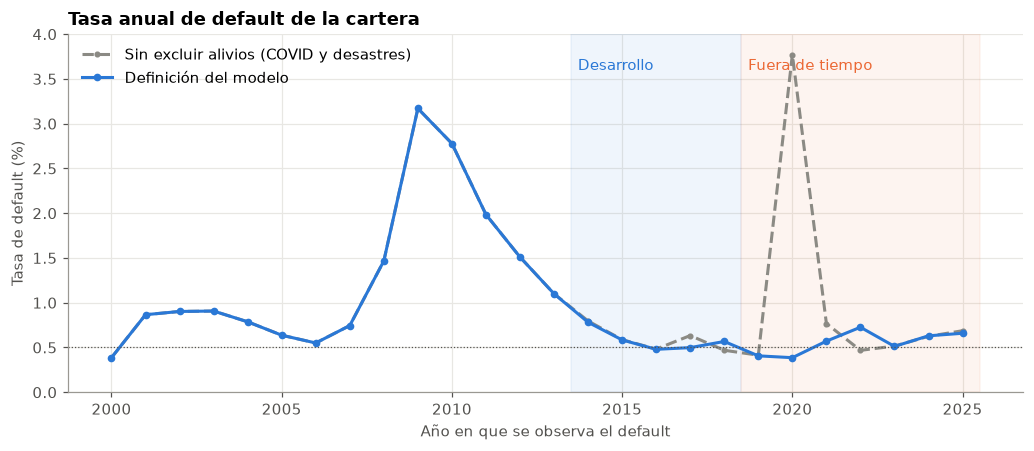

,créditos,defaults,tasa (%),tasa sin excluir alivios (%),tasa sin reestructuras (%)
año del default,,,,,
2000,39052,151,0.387,0.387,0.387
2001,85550,741,0.866,0.866,0.866
2002,105273,950,0.902,0.902,0.900
2003,114980,1043,0.907,0.907,0.905
2004,105595,831,0.787,0.787,0.783
2005,129935,828,0.637,0.637,0.636
2006,157757,868,0.550,0.550,0.548
2007,188315,1403,0.745,0.745,0.745
2008,219000,3213,1.467,1.467,1.446


In [14]:
def tasas_anuales(elig, y):
    return (cohortes.filter(pl.col(elig)).group_by('corte')
            .agg(creditos=pl.len(), defaults=pl.col(y).sum(), tasa=pl.col(y).mean()).sort('corte').to_pandas()
            .set_index('corte'))

anual = tasas_anuales(elig_col, y_col)
anual_bruta = tasas_anuales('elig_ev_bruto', 'y_ev_bruto')
anual_sinmod = tasas_anuales('elig_ev_sinmod', 'y_ev_sinmod')

fig, ax = plt.subplots(figsize=(9.5, 4.2))
anios = anual.index + 1
ax.axvspan(CORTES_DESARROLLO[0] + 0.5, CORTES_DESARROLLO[1] + 1.5, color=AZUL, alpha=0.07)
ax.axvspan(CORTES_OOT[0] + 0.5, CORTES_OOT[1] + 1.5, color=NARANJA, alpha=0.07)
ax.plot(anios, anual_bruta['tasa'] * 100, color=GRIS, linestyle='--', marker='o', markersize=3, label='Sin excluir alivios (COVID y desastres)')
ax.plot(anios, anual['tasa'] * 100, color=AZUL, marker='o', markersize=4, label='Definición del modelo')
ax.axhline(0.5, color=TINTA, linewidth=0.8, linestyle=':')
ax.text(CORTES_DESARROLLO[0] + 0.7, 3.6, 'Desarrollo', color=AZUL)
ax.text(CORTES_OOT[0] + 0.7, 3.6, 'Fuera de tiempo', color=NARANJA)
ax.set(title='Tasa anual de default de la cartera', xlabel='Año en que se observa el default', ylabel='Tasa de default (%)', ylim=(0, 4))
ax.legend(loc='upper left')
mostrar(fig, 'tasa_default_anual')

tabla = pd.DataFrame({'créditos': anual['creditos'], 'defaults': anual['defaults'], 'tasa (%)': anual['tasa'] * 100,
                      'tasa sin excluir alivios (%)': anual_bruta['tasa'] * 100,
                      'tasa sin reestructuras (%)': anual_sinmod['tasa'] * 100})
tabla.index = (tabla.index + 1).rename('año del default')
tabla.round(3)

**Lectura.**

- **El ciclo completo está en los datos.** La tasa estuvo entre 0.39 % y 0.91 % de 2000 a 2007, saltó a 3.17 % en 2009 y bajó gradualmente hasta 0.48 % en 2016. Desde entonces se mueve entre 0.39 % y 0.73 %.
- **El desarrollo cae en años buenos.** De 2014 a 2018 la tasa va de 0.48 % a 0.78 %. Es el ~0.5 % de una cartera de bajo default, pero no representa el ciclo. Un modelo entrenado solo con esos años aprende el nivel de los años buenos, y lo corregiremos en la calibración (sección 9).
- **Sin la excepción por alivio, 2020 parecería peor que la crisis de 2009:** 3.77 % frente a 3.17 %. Con la excepción, 2020 queda en 0.39 %. En 2017 aparece el mismo efecto en menor escala (0.63 % frente a 0.50 %) por los atrasos que dejaron los huracanes Harvey, Irma y María.
- **En 2022 ocurre lo contrario.** Con la definición del modelo, los créditos que se atrasaron durante el alivio siguen en la cartera, y algunos incumplen cuando el alivio termina. Por eso 2022 queda en 0.73 %, frente a 0.47 % sin la excepción.
- **Las reestructuras importan en dos momentos:** en la crisis (2010: 2.78 % frente a 2.66 % sin contarlas) y a la salida del COVID (2022: 0.73 % frente a 0.52 %), cuando la reestructura fue la salida del *forbearance* para muchos deudores.

## 5. Muestras

### Teoría: entrenamiento, prueba y fuera de tiempo

Un modelo se evalúa con datos que no vio al aprender. Se usan tres muestras, cada una con un propósito:

| Muestra | Para qué se usa | Pregunta que responde |
|---|---|---|
| **Entrenamiento** | Ajustar tramos, WoE y coeficientes | ¿Qué patrones hay? |
| **Prueba** | Elegir entre modelos | ¿Cuál generaliza mejor a créditos nuevos del mismo período? |
| **Fuera de tiempo** | Prueba final, sin tomar decisiones con ella | ¿Funciona en años que todavía no habían ocurrido? |

**La trampa del mismo crédito en varios cortes.** Un crédito vigente durante cinco años aparece en cinco cohortes. Si se reparten las *filas* al azar, sus filas quedan a la vez en entrenamiento y en prueba, y el modelo se evalúa sobre clientes que ya conoce. La solución es repartir **créditos completos**.

**Ejemplo mínimo.** 100 créditos que aparecen en 3 cortes cada uno, separados 70/30 de las dos formas.

In [15]:
j_rng = np.random.default_rng(SEMILLA)
j_filas = pd.DataFrame({'crédito': np.repeat(np.arange(100), 3), 'corte': np.tile([2015, 2016, 2017], 100)})
j_por_fila = j_rng.random(len(j_filas)) < 0.7
j_creditos_train = set(j_rng.choice(100, 70, replace=False))
j_por_credito = j_filas['crédito'].isin(j_creditos_train).to_numpy()
for nombre, en_train in [('Separación por fila', j_por_fila), ('Separación por crédito', j_por_credito)]:
    comunes = set(j_filas.loc[en_train, 'crédito']) & set(j_filas.loc[~en_train, 'crédito'])
    print(f'{nombre}: {len(comunes)} de 100 créditos aparecen a la vez en entrenamiento y en prueba')

Separación por fila: 60 de 100 créditos aparecen a la vez en entrenamiento y en prueba
Separación por crédito: 0 de 100 créditos aparecen a la vez en entrenamiento y en prueba


**Errores comunes**

- **Separar por fila cuando un cliente aparece varias veces.** La prueba queda contaminada y el desempeño, inflado.
- **Mirar la muestra fuera de tiempo para elegir el modelo.** Deja de ser una prueba y pasa a ser parte del ajuste.
- **Usar una validación cruzada al azar** en un problema que cambia en el tiempo. Mezcla años y sobrestima el desempeño futuro (sección 12).

**El presupuesto de eventos.** Con pocos defaults, un modelo con muchos parámetros memoriza ruido. La referencia habitual pide **entre 10 y 20 defaults de entrenamiento por parámetro**.

---

### Aplicación al proyecto

| Muestra | Cortes | Uso |
|---|---|---|
| **Entrenamiento** | 2013–2017, 70 % de los créditos | Ajustar tramos, WoE y modelos |
| **Prueba de desarrollo** | 2013–2017, 30 % de los créditos | Elegir el modelo con la regla fijada de antemano |
| **Fuera de tiempo (OOT)** | 2018–2024 | Prueba final, que no se usa para ninguna decisión |
| **Ciclo** | 2003–2017 | Tendencia central de la calibración |

**Separación por crédito.** Un crédito aparece en varios cortes. Si una de sus filas cayera en entrenamiento y otra en prueba, el modelo se evaluaría sobre créditos que ya conoce. Por eso asignamos cada crédito completo a una sola muestra.

**Por qué desarrollo 2013–2017.** Son años de tasa cercana al 0.5 %, posteriores a la crisis y con las reglas de originación actuales. La crisis se incorpora después, en la calibración, que es donde corresponde según la guía: el modelo ordena y la calibración fija el nivel.

In [16]:
mapa_na = {c: v for c, v in ESPECIALES.items()}

def numero(col):
    x = pl.col(col).str.strip_chars()
    return pl.when(x == mapa_na.get(col, '__')).then(None).otherwise(x).cast(pl.Float64)

def categoria(col):
    x = pl.col(col).str.strip_chars()
    return pl.when(x == mapa_na.get(col, '__')).then(pl.lit('ND')).otherwise(x)

CATEGORIAS = {}

def preparar(c, atraso_sin_alivio=None):
    atraso_sin_alivio = ATRASO_SIN_ALIVIO if atraso_sin_alivio is None else atraso_sin_alivio
    c = c.with_columns(
        fico=numero('fico'), dti=numero('dti'), ltv=numero('ltv'), cltv=numero('cltv'), seguro=numero('seguro_pct'),
        n_deudores=numero('n_deudores'), unidades=numero('unidades'), plazo=numero('plazo'), monto=numero('monto'),
        tasa_orig=numero('tasa_orig'),
        ocupacion=categoria('ocupacion'), canal=categoria('canal'), proposito=categoria('proposito'),
        tipo_prop=categoria('tipo_prop'), primer_comprador=categoria('primer_comprador'), estado=categoria('estado'))
    aj = '_aj' if atraso_sin_alivio else ''
    c = c.with_columns(
        sobretasa_orig=pl.col('tasa_orig') - pl.col('tasa_mercado_orig'),
        brecha_tasa=pl.col('tasa_actual') - pl.col('tasa_mercado_corte'),
        ltv_actual=pl.col('saldo') / (pl.col('monto') / pl.col('ltv') * 100) * 100,
        atraso_actual=pl.col('dq' + aj), max_atraso_12m=pl.col('max_atraso_12m' + aj),
        meses_mora_12m=pl.col('meses_mora_12m' + aj))
    cols = ['id', 'corte', 'cosecha', 'default', 'saldo'] + NUMERICAS + CATEGORICAS
    d = c.rename({y_col: 'default'}).select(cols).to_pandas()
    for k in CATEGORICAS:
        # Las mismas categorías en todas las muestras; una categoría nueva queda como faltante
        d[k] = pd.Categorical(d[k], categories=CATEGORIAS[k]) if k in CATEGORIAS else d[k].astype('category')
        CATEGORIAS.setdefault(k, d[k].cat.categories)
    return d

ORIGINACION = ['fico', 'ltv', 'cltv', 'dti', 'seguro', 'sobretasa_orig', 'plazo', 'n_deudores', 'unidades']
COMPORTAMIENTO = ['meses', 'atraso_actual', 'max_atraso_12m', 'meses_mora_12m', 'alivio_12m', 'modificado',
                  'diferido', 'ltv_actual', 'brecha_tasa']
NUMERICAS = ORIGINACION + COMPORTAMIENTO
CATEGORICAS = ['ocupacion', 'canal', 'proposito', 'tipo_prop', 'primer_comprador', 'estado']
POOL = NUMERICAS + CATEGORICAS

datos = preparar(cohortes.filter(pl.col(elig_col)))
datos['periodo'] = np.select([datos.corte.between(*CORTES_DESARROLLO), datos.corte.between(*CORTES_OOT)],
                             ['desarrollo', 'oot'], 'historia')
rng = np.random.default_rng(SEMILLA)
ids_dev = datos.loc[datos.periodo == 'desarrollo', 'id'].unique()
ids_test = set(rng.choice(ids_dev, int(len(ids_dev) * PROPORCION_TEST), replace=False))
datos.loc[(datos.periodo == 'desarrollo') & datos.id.isin(ids_test), 'periodo'] = 'test'
datos.loc[datos.periodo == 'desarrollo', 'periodo'] = 'train'

train, test, oot = (datos[datos.periodo == k].reset_index(drop=True) for k in ['train', 'test', 'oot'])
resumen = datos[datos.periodo != 'historia'].groupby('periodo', observed=True).agg(
    filas=('default', 'size'), creditos=('id', 'nunique'), defaults=('default', 'sum'), tasa=('default', 'mean'))
resumen['tasa'] = resumen['tasa'].map(pct)
assert not set(train.id) & set(test.id), 'Un crédito no puede estar en entrenamiento y prueba'
resumen.loc[['train', 'test', 'oot']]

,filas,creditos,defaults,tasa
periodo,,,,
train,913163,296425,5219,0.57 %
test,392136,127039,2294,0.59 %
oot,2034470,599960,11209,0.55 %


### El presupuesto de eventos

Con pocos defaults, el riesgo es que el modelo memorice ruido. Una referencia conocida pide **entre 10 y 20 defaults de entrenamiento por parámetro**. Un parámetro es cada coeficiente que se estima: en una logística con WoE, uno por variable; si una variable entra como categorías, uno por categoría menos una.

In [17]:
d_train = int(train.default.sum())
print(f'Defaults de entrenamiento: {d_train:,}')
print(f'Presupuesto con {EVENTOS_POR_PARAMETRO} por parámetro: hasta {d_train // EVENTOS_POR_PARAMETRO} parámetros '
      f'(con 20 por parámetro: {d_train // 20})')

Defaults de entrenamiento: 5,219
Presupuesto con 10 por parámetro: hasta 521 parámetros (con 20 por parámetro: 260)


**Lectura.** Con 5,219 defaults de entrenamiento, el presupuesto admite hasta 521 parámetros, o 260 con el criterio prudente de 20 por parámetro. Como el modelo usará alrededor de 12, la restricción no es activa.

**Dónde está el bajo default en esta cartera.** La tasa es de 0.57 %, pero con cinco años de una muestra grande se acumulan miles de eventos. Un banco mediano, con 50,000 hipotecas y la misma tasa, tendría unos 250 defaults por año, y con un solo año de datos el presupuesto bajaría a 12–25 parámetros. Aquí la escasez aparece en otro lugar: en los mejores grados de riesgo, que acumulan muy pocos defaults (sección 9).

## 6. Selección de variables

### Teoría: WoE, IV, PSI y VIF a mano

**WoE (peso de evidencia).** Se divide la variable en tramos y, para cada tramo, se compara su parte de los buenos con su parte de los malos:

*WoE = ln(% de los buenos de la cartera que están en el tramo ÷ % de los malos que están en el tramo)*

Si un tramo tiene más buenos que malos en proporción, su WoE es positivo (tramo seguro); si tiene más malos, negativo (tramo riesgoso).

**IV (valor de información)** suma, para todos los tramos, *(% buenos − % malos) × WoE*. Mide cuánto separa la variable a quienes incumplen. Referencias habituales: menos de 0.02 no aporta, 0.02 a 0.1 es débil, 0.1 a 0.3 es media y más de 0.3 es fuerte. Un IV muy alto merece revisar que no haya fuga de información.

**Ejemplo mínimo.** Un FICO dividido en tres tramos, con 1,000 buenos y 20 malos en total.

In [18]:
j_tramos = pd.DataFrame({'tramo': ['< 680', '680–760', '> 760'], 'buenos': [200, 450, 350], 'malos': [12, 6, 2]})
j_tramos['% buenos'] = j_tramos['buenos'] / j_tramos['buenos'].sum()
j_tramos['% malos'] = j_tramos['malos'] / j_tramos['malos'].sum()
j_tramos['tasa de default'] = j_tramos['malos'] / (j_tramos['buenos'] + j_tramos['malos'])
j_tramos['WoE'] = np.log(j_tramos['% buenos'] / j_tramos['% malos'])
j_tramos['aporte al IV'] = (j_tramos['% buenos'] - j_tramos['% malos']) * j_tramos['WoE']
display(j_tramos.round(3))
print(f"IV total: {j_tramos['aporte al IV'].sum():.3f}")

,tramo,buenos,malos,% buenos,% malos,tasa de default,WoE,aporte al IV
0,< 680,200,12,0.20,0.6,0.057,-1.099,0.439
1,680–760,450,6,0.45,0.3,0.013,0.405,0.061
2,> 760,350,2,0.35,0.1,0.006,1.253,0.313


IV total: 0.813


**Qué muestra el ejemplo.** La tasa baja de un tramo al siguiente y el WoE sube: la relación es monotónica, como se espera del FICO. El tramo más riesgoso tiene el 20 % de los buenos pero el 60 % de los malos, y aporta la mayor parte del IV.

**PSI (índice de estabilidad).** Compara la distribución de una variable entre dos momentos, tramo por tramo:

*PSI = Σ (% actual − % de referencia) × ln(% actual ÷ % de referencia)*

Referencias habituales: menos de 0.10 es estable, de 0.10 a 0.25 hay que revisar y más de 0.25 es un cambio importante.

**VIF (factor de inflación de la varianza).** Mide cuánto de una variable se puede predecir con las demás: *VIF = 1 ÷ (1 − R²)*. Si el R² es 0.8, el VIF es 5. Un VIF alto vuelve inestables los coeficientes de la logística, aunque no empeore el orden.

In [19]:
j_ref, j_act = np.array([0.20, 0.45, 0.35]), np.array([0.30, 0.45, 0.25])
print(f'PSI entre las dos distribuciones: {np.sum((j_act - j_ref) * np.log(j_act / j_ref)):.3f}')

j_rng = np.random.default_rng(SEMILLA)
j_x1 = j_rng.normal(size=5_000)
for ruido in (2.0, 0.5, 0.2):
    j_x2 = j_x1 + j_rng.normal(scale=ruido, size=5_000)
    j_r2 = np.corrcoef(j_x1, j_x2)[0, 1] ** 2
    print(f'ruido {ruido}: correlación {np.sqrt(j_r2):.2f}, VIF {1 / (1 - j_r2):.1f}')

PSI entre las dos distribuciones: 0.074
ruido 2.0: correlación 0.42, VIF 1.2
ruido 0.5: correlación 0.89, VIF 4.9
ruido 0.2: correlación 0.98, VIF 25.7


**Errores comunes**

- **Hacer tramos con pocos defaults.** El WoE de un tramo con 3 defaults es casi puro azar. Con eventos raros, el tamaño mínimo se fija en defaults, no en créditos.
- **Elegir variables solo por IV.** Dos variables con IV alto pueden decir lo mismo; por eso se revisan la correlación y el VIF.
- **Calcular el PSI con la muestra de prueba.** La selección debe hacerse solo con entrenamiento.

> **Pruébalo.** En la tabla de tramos, cambia los malos del tramo `> 760` de 2 a 0. ¿Qué le pasa al WoE? Así se entiende por qué el código suma 0.5 casos a cada tramo.

---

**Aplicación al proyecto.** Ahora llevamos estas ideas a los datos de Freddie Mac.

### Las candidatas

Partimos de 24 variables. Excluimos de antemano tres tipos de información:

- **Niveles nominales que dependen de la época,** como la tasa, el monto o el saldo. Una tasa de 7 % en 2023 no es más riesgosa que una de 4 % en 2015; refleja el mercado. En su lugar usamos diferencias contra la tasa de mercado y el LTV, que no depende de la inflación.
- **El LTV estimado de Freddie Mac (ELTV),** porque solo existe desde 2017 y no permitiría usar el ciclo.
- **Identificadores y datos del administrador,** como el vendedor o el código postal, que no describen al deudor.

| Variable | Grupo | Definición |
|---|---|---|
| `fico` | Originación | Puntaje de crédito al otorgar el préstamo |
| `ltv`, `cltv` | Originación | Préstamo sobre valor del inmueble; el CLTV suma otros préstamos sobre la misma vivienda |
| `dti` | Originación | Pagos de deuda sobre ingreso |
| `seguro` | Originación | Porcentaje cubierto por seguro hipotecario |
| `sobretasa_orig` | Originación | Tasa del crédito menos la tasa de mercado del mismo mes: el precio por riesgo |
| `plazo`, `n_deudores`, `unidades` | Originación | Plazo en meses, número de deudores y de viviendas |
| `ocupacion`, `canal`, `proposito`, `tipo_prop`, `primer_comprador`, `estado` | Originación | Uso de la vivienda, canal de venta, compra o refinanciamiento, tipo de inmueble, primera vivienda y estado |
| `meses` | Comportamiento | Antigüedad del crédito al corte |
| `atraso_actual` | Comportamiento | Tramo de atraso al corte: 0, 30 o 60 días |
| `max_atraso_12m`, `meses_mora_12m` | Comportamiento | Peor atraso y meses con atraso en los últimos 12 meses |
| `alivio_12m`, `modificado`, `diferido` | Comportamiento | Si tuvo *forbearance*, reestructura o diferimiento de pagos |
| `ltv_actual` | Comportamiento | Saldo actual sobre el valor del inmueble al originar |
| `brecha_tasa` | Comportamiento | Tasa actual menos la tasa de mercado al corte: incentivo a refinanciar |

### Cómo se agrupa una variable: tramos y WoE

Para una regresión logística clásica, cada variable se divide en tramos y cada tramo se reemplaza por su **peso de evidencia (WoE)**:

`WoE = ln( % de los que no incumplen en el tramo / % de los que incumplen en el tramo )`

Un WoE positivo indica un tramo más seguro que el promedio. Los tramos se construyen así, solo con entrenamiento:

1. Se parte de 20 cuantiles, o de cada valor si la variable tiene 25 valores distintos o menos (como los meses con atraso).
2. Si la relación tiene sentido económico en una dirección (más FICO, menos riesgo), se unen tramos vecinos hasta que la tasa de default sea monotónica.
3. Se unen los tramos con menos de `MIN_DEFAULTS_TRAMO` defaults o menos de `MIN_PROP_TRAMO` de la población. **Con bajo default, lo que limita es el número de defaults, no el de créditos.** Por eso el mínimo de población es bajo (0.5 %): los créditos con atraso son menos del 1 % de la cartera, pero concentran una parte grande de los defaults. Un mínimo de 2 % o más los mezclaría con los créditos al día y borraría justo la información más valiosa.
4. Los faltantes forman su propio tramo. Una categoría nueva en operación recibe WoE 0, es decir, riesgo promedio.

Las categorías se ordenan por su tasa de default y se agrupan con las mismas reglas de tamaño. `meses` se agrupa sin exigir monotonía, porque el riesgo de una hipoteca sube en los primeros años y luego baja.

### Las medidas de selección

| Medida | Qué responde | Umbral |
|---|---|---|
| **% faltante y concentración** | ¿Hay suficiente información? | Faltante ≤ 50 % y categoría dominante ≤ 99.5 % |
| **IV** (valor de información) | ¿Cuánto separa la variable a quienes incumplen? `Σ (%buenos − %malos) × WoE` | ≥ 0.02 |
| **Gini univariado** | Lo mismo, en la escala de Gini, con intervalo por *bootstrap* | Informativo |
| **PSI** (índice de estabilidad) | ¿Cambió la distribución entre el primer y el último año de entrenamiento? | ≤ 0.25 |
| **Correlación** | ¿Repite lo que dice otra variable? Se conserva la de mayor IV | ≤ 0.70 |
| **VIF** | ¿Se puede predecir con las demás variables juntas? | ≤ 5 |
| **Signo y significancia** | ¿El coeficiente tiene la dirección esperada y es distinto de cero? | p ≤ 0.05 |

El PSI se calcula dentro del entrenamiento (2013 contra 2017). Así la muestra fuera de tiempo no influye en ninguna decisión.

In [20]:
def woe(buenos, malos, B, M):
    return np.log(((buenos + 0.5) / (B + 0.5)) / ((malos + 0.5) / (M + 0.5)))

def unir(n, d, etiquetas, i):
    # Une el tramo i con el i+1
    n[i] += n[i + 1]; d[i] += d[i + 1]
    etiquetas[i] = etiquetas[i] + etiquetas[i + 1]
    del n[i + 1], d[i + 1], etiquetas[i + 1]

def reducir_por_tamano(n, d, etiquetas, total):
    while len(n) > 1:
        debil = [k for k in range(len(n)) if d[k] < MIN_DEFAULTS_TRAMO or n[k] < MIN_PROP_TRAMO * total]
        if not debil:
            break
        k = min(debil, key=lambda j: d[j])
        tasa = [d[j] / n[j] for j in range(len(n))]
        vecinos = [j for j in (k - 1, k + 1) if 0 <= j < len(n)]
        j = min(vecinos, key=lambda v: abs(tasa[v] - tasa[k]))
        unir(n, d, etiquetas, min(j, k))

def ajustar_tramos(x, y, nombre, categorica=False, monotona=True):
    y = np.asarray(y, dtype=float)
    B, M = (1 - y).sum(), y.sum()
    if categorica:
        x = x.astype(str).to_numpy()
        tab = pd.DataFrame({'x': x, 'y': y}).groupby('x')['y'].agg(['size', 'sum'])
        tab = tab.assign(t=(tab['sum'] + 0.5) / (tab['size'] + 1)).sort_values('t')
        n, d, etiquetas = list(tab['size'].astype(float)), list(tab['sum']), [[c] for c in tab.index]
        reducir_por_tamano(n, d, etiquetas, len(y))
        w = [woe(n[k] - d[k], d[k], B, M) for k in range(len(n))]
        return {'tipo': 'cat', 'grupos': etiquetas, 'woe': w, 'n': n, 'd': d, 'nombre': nombre}
    x = np.asarray(x, dtype=float)
    ok = ~np.isnan(x)
    distintos = np.unique(x[ok])
    # Pocas categorías numéricas (por ejemplo, meses con atraso): cada valor es un tramo inicial
    cortes = list(distintos[:-1]) if len(distintos) <= 25 else list(np.unique(np.quantile(x[ok], np.linspace(0, 1, 21)[1:-1])))
    idx = np.searchsorted(cortes, x[ok], side='left')
    n = list(np.bincount(idx, minlength=len(cortes) + 1).astype(float))
    d = list(np.bincount(idx, weights=y[ok], minlength=len(cortes) + 1))
    etiquetas = [[i] for i in range(len(n))]
    vacios = [k for k in range(len(n)) if n[k] == 0]
    for k in reversed(vacios):
        unir(n, d, etiquetas, k - 1 if k > 0 else k)
    signo = float(np.nan_to_num(np.sign(np.corrcoef(x[ok], y[ok])[0, 1]))) if monotona else 0.0
    if signo != 0:
        cambio = True
        while cambio and len(n) > 1:
            cambio = False
            for k in range(len(n) - 1):
                if (d[k + 1] / n[k + 1] - d[k] / n[k]) * signo < 0:
                    unir(n, d, etiquetas, k); cambio = True; break
    reducir_por_tamano(n, d, etiquetas, ok.sum())
    superiores = [cortes[e[-1]] if e[-1] < len(cortes) else np.inf for e in etiquetas]
    n_na, d_na = float((~ok).sum()), float(y[~ok].sum())
    return {'tipo': 'num', 'cortes': superiores, 'woe': [woe(n[k] - d[k], d[k], B, M) for k in range(len(n))],
            'woe_na': woe(n_na - d_na, d_na, B, M) if n_na > 0 else 0.0, 'n': n, 'd': d, 'n_na': n_na, 'd_na': d_na,
            'signo': signo, 'nombre': nombre}

def transformar(x, t):
    if t['tipo'] == 'cat':
        mapa = {c: w for g, w in zip(t['grupos'], t['woe']) for c in g}
        return pd.Series(x.astype(str)).map(mapa).fillna(0.0).to_numpy()
    x = np.asarray(x, dtype=float)
    k = np.minimum(np.searchsorted(t['cortes'], x, side='left'), len(t['cortes']) - 1)
    return np.where(np.isnan(x), t['woe_na'], np.asarray(t['woe'])[k])

def indice_tramo(x, t):
    # Número de tramo de cada observación; el faltante es el último
    if t['tipo'] == 'cat':
        mapa = {c: i for i, g in enumerate(t['grupos']) for c in g}
        return pd.Series(x.astype(str)).map(mapa).fillna(len(t['grupos'])).astype(int).to_numpy()
    x = np.asarray(x, dtype=float)
    k = np.minimum(np.searchsorted(t['cortes'], x, side='left'), len(t['cortes']) - 1)
    return np.where(np.isnan(x), len(t['cortes']), k)

def psi(a, b, t):
    k = len(t['woe']) + 1
    p = np.bincount(indice_tramo(a, t), minlength=k) / len(a)
    q = np.bincount(indice_tramo(b, t), minlength=k) / len(b)
    p, q = np.clip(p, 1e-6, None), np.clip(q, 1e-6, None)
    return float(np.sum((p - q) * np.log(p / q)))

def tabla_tramos(t):
    if t['tipo'] == 'cat':
        etiqueta = [', '.join(g) if len(g) <= 6 else f'{len(g)} categorías' for g in t['grupos']]
        n, d, w = t['n'], t['d'], t['woe']
    else:
        lim = [-np.inf] + t['cortes']
        etiqueta = [f'({lim[i]:.4g}, {lim[i + 1]:.4g}]' for i in range(len(t['cortes']))]
        n, d, w = list(t['n']), list(t['d']), list(t['woe'])
        if t['n_na'] > 0:
            etiqueta.append('Faltante'); n.append(t['n_na']); d.append(t['d_na']); w.append(t['woe_na'])
    n, d = np.array(n), np.array(d)
    B, M = (n - d).sum(), d.sum()
    out = pd.DataFrame({'tramo': etiqueta, 'créditos': n.astype(int), '% población': n / n.sum() * 100,
                        'defaults': d.astype(int), 'tasa (%)': d / n * 100, 'WoE': w})
    out['IV'] = ((n - d) / B - d / M) * out['WoE']
    return out.round(3)

def iv(t):
    return float(tabla_tramos(t)['IV'].sum())

### Ejemplo paso a paso: `fico`

Antes de aplicar los filtros a todas las variables, veamos la tabla de tramos del FICO. Fíjate en tres cosas: la tasa de default baja de un tramo al siguiente, el WoE sube, y el aporte al IV se concentra en los extremos.

In [21]:
NO_MONOTONAS = ['meses']
tramos = {v: ajustar_tramos(train[v], train.default, v, categorica=v in CATEGORICAS, monotona=v not in NO_MONOTONAS)
          for v in POOL}
tabla_tramos(tramos['fico'])

,tramo,créditos,% población,defaults,tasa (%),WoE,IV
0,"(-inf, 652]",46948,5.141,1009,2.149,-1.341,0.191
1,"(652, 676]",45459,4.978,726,1.597,-1.039,0.093
2,"(676, 692]",47574,5.210,550,1.156,-0.711,0.038
3,"(692, 704]",45604,4.994,432,0.947,-0.510,0.017
4,"(704, 715]",45701,5.005,379,0.829,-0.376,0.009
5,"(715, 725]",44851,4.912,328,0.731,-0.250,0.003
6,"(725, 744]",92675,10.149,501,0.541,0.055,0.000
7,"(744, 752]",44876,4.914,192,0.428,0.289,0.004
8,"(752, 760]",49161,5.384,197,0.401,0.354,0.006
9,"(760, 766]",39529,4.329,121,0.306,0.623,0.013


**Lectura.**

- **El patrón es monotónico, como se espera.** La tasa baja de 2.15 % con FICO hasta 652 a 0.13 % con más de 809, unas 16 veces menos. El WoE sube de −1.34 a +1.48.
- **Con 20 cuantiles iniciales, el FICO conserva 19 tramos.** Solo se unieron dos tramos vecinos que rompían la monotonía; todos tienen más de 30 defaults.
- **El IV total es 0.73,** muy por encima del mínimo de 0.02. El mayor aporte (0.19) viene del tramo más riesgoso, que tiene el 5 % de la población pero el 19 % de los defaults.
- **El tramo de faltantes tiene solo 354 créditos y 5 defaults.** Su WoE (−1.01) es poco confiable y depende del suavizado de 0.5 casos. En producción, conviene asignar a esos casos el WoE del tramo más riesgoso y documentar la regla.

### Gini univariado con incertidumbre

Con pocos defaults, una diferencia de Gini entre dos variables puede ser azar. Calculamos un intervalo por ***bootstrap* por crédito**: en cada réplica, cada crédito recibe un peso aleatorio de Poisson(1) que se aplica a todas sus filas. Así se respeta que el mismo crédito aparece en varios cortes.

Para que 300 réplicas sobre millones de filas tomen segundos, el AUC se calcula con sumas acumuladas sobre los valores distintos del score, en lugar de reordenar en cada réplica.

In [22]:
class Evaluador:
    # Gini y PR AUC ponderados sobre un orden fijo; permite bootstrap por crédito en segundos.
    # El PR AUC se estima con la precisión promedio (AP), en escalones; no es el área trapezoidal
    def __init__(self, y, s, ids):
        self.y = np.asarray(y, dtype=float)
        self.valores, self.grupo = np.unique(np.asarray(s, dtype=float), return_inverse=True)
        self.codigos, self.n_ids = pd.factorize(np.asarray(ids))[0], None
        self.n_ids = self.codigos.max() + 1

    def metricas(self, w=None):
        w = np.ones_like(self.y) if w is None else w
        k = len(self.valores)
        pos = np.bincount(self.grupo, weights=w * self.y, minlength=k)
        neg = np.bincount(self.grupo, weights=w * (1 - self.y), minlength=k)
        P, N = pos.sum(), neg.sum()
        auc = (np.sum(pos * (np.cumsum(neg) - neg)) + 0.5 * np.sum(pos * neg)) / (P * N)
        vp, fp = np.cumsum(pos[::-1]), np.cumsum(neg[::-1])
        precision = np.divide(vp, vp + fp, out=np.zeros_like(vp), where=(vp + fp) > 0)
        pr_auc = np.sum(precision * pos[::-1]) / P
        return 2 * auc - 1, pr_auc

    def pesos(self, rng):
        return rng.poisson(1.0, self.n_ids)[self.codigos].astype(float)

def bootstrap(y, scores, ids, n=N_BOOTSTRAP, semilla=SEMILLA):
    # Remuestreo pareado: todos los scores usan los mismos pesos en cada réplica
    evs = {k: Evaluador(y, s, ids) for k, s in scores.items()}
    rng = np.random.default_rng(semilla)
    base = next(iter(evs.values()))
    salida = {k: [] for k in scores}
    for _ in range(n):
        w = base.pesos(rng)
        for k, ev in evs.items():
            salida[k].append(ev.metricas(w))
    puntual = {k: ev.metricas() for k, ev in evs.items()}
    return puntual, {k: np.array(v) for k, v in salida.items()}

def ic(x, d=3):
    lo, hi = np.percentile(x, [2.5, 97.5])
    return f'{lo:.{d}f} a {hi:.{d}f}'

In [23]:
woe_train = pd.DataFrame({v: transformar(train[v], tramos[v]) for v in POOL})
primer, ultimo = train.corte == CORTES_DESARROLLO[0], train.corte == CORTES_DESARROLLO[1]
puntual, boot = bootstrap(train.default, {v: -woe_train[v] for v in POOL}, train.id, n=200)
filtro = pd.DataFrame({
    'grupo': ['Originación' if v in ORIGINACION or v in CATEGORICAS else 'Comportamiento' for v in POOL],
    'faltante': [train[v].isna().mean() if v in NUMERICAS else (train[v] == 'ND').mean() for v in POOL],
    'concentración': [train[v].value_counts(normalize=True, dropna=False).iloc[0] for v in POOL],
    'tramos': [len(tramos[v]['woe']) for v in POOL],
    'IV': [iv(tramos[v]) for v in POOL],
    'Gini': [puntual[v][0] for v in POOL],
    'Gini IC 95 %': [ic(boot[v][:, 0]) for v in POOL],
    'PSI 2013 vs 2017': [psi(train.loc[primer, v], train.loc[ultimo, v], tramos[v]) for v in POOL],
}, index=POOL)
filtro['motivo'] = np.select(
    [filtro['faltante'] > MAX_FALTANTES, filtro['concentración'] > CONCENTRACION_MAX, filtro['IV'] < IV_MIN,
     filtro['PSI 2013 vs 2017'] > PSI_MAX],
    ['faltantes', 'concentración', 'IV bajo', 'PSI alto'], '')
filtro.sort_values('IV', ascending=False).round(3)

,grupo,faltante,concentración,tramos,IV,Gini,Gini IC 95 %,PSI 2013 vs 2017,motivo
max_atraso_12m,Comportamiento,0.000,0.968,3,2.533,0.575,0.561 a 0.589,0.001,
meses_mora_12m,Comportamiento,0.000,0.968,4,2.395,0.575,0.561 a 0.589,0.001,
atraso_actual,Comportamiento,0.000,0.990,2,2.107,0.449,0.437 a 0.466,0.000,
fico,Originación,0.000,0.013,19,0.727,0.465,0.452 a 0.478,0.005,
brecha_tasa,Comportamiento,0.000,0.018,19,0.675,0.445,0.428 a 0.458,0.803,PSI alto
meses,Comportamiento,0.000,0.017,20,0.308,0.297,0.279 a 0.314,0.242,
sobretasa_orig,Originación,0.000,0.002,14,0.300,0.300,0.284 a 0.313,0.021,
canal,Originación,0.000,0.630,4,0.207,0.202,0.188 a 0.215,0.112,
cltv,Originación,0.000,0.172,12,0.180,0.225,0.210 a 0.240,0.031,
dti,Originación,0.208,0.208,14,0.158,0.213,0.197 a 0.227,0.083,


**Lectura.**

- **El historial de atraso es lo más informativo.** `max_atraso_12m` tiene un IV de 2.53 y un Gini de 0.575, aunque solo el 3.2 % de los créditos tuvo algún atraso en el año. Así se ve el bajo default: la información está concentrada en pocos casos. Con un tamaño mínimo de tramo de 2 % de la población, `atraso_actual` (1 % de los créditos tiene atraso al corte) habría quedado en un solo tramo, sin ninguna información.
- **Entre las de originación, el FICO es la más fuerte** (IV 0.73), seguido por la sobretasa al originar (0.30), que mide el precio que puso el originador por el riesgo.
- **`brecha_tasa` se descarta por inestable (PSI 0.80).** Entre 2013 y 2017 cambió el entorno de tasas, así que el incentivo a refinanciar se distribuye distinto aunque los deudores sean iguales. `meses` pasa justo (PSI 0.24), porque la cartera envejece de un año a otro.
- **Tres variables no varían en el entrenamiento:** `diferido`, `modificado` y `alivio_12m`. Los diferimientos y los *forbearance* masivos aparecieron con el COVID, y un crédito reestructurado ya está en default según nuestra definición. **El modelo no puede aprender el efecto de algo que nunca vio**, y esa es una limitación para los años de pandemia.
- **Los intervalos ayudan a no sobreinterpretar.** El Gini de `cltv` (0.210 a 0.240) y el de `ltv` (0.194 a 0.221) se solapan, así que no se puede afirmar que uno sea mejor que el otro.

### Redundancia: correlación y VIF

Entre las que pasan, buscamos pares que digan lo mismo. Si dos variables tienen una correlación de WoE mayor a 0.70, conservamos la de mayor IV. Después, retiramos una a una las que tengan VIF mayor a 5.

In [24]:
pasan = filtro.index[filtro['motivo'] == ''].tolist()
orden_iv = filtro.loc[pasan, 'IV'].sort_values(ascending=False).index.tolist()
corr = woe_train[pasan].corr()
conservar, retiradas = [], {}
for v in orden_iv:
    choque = [k for k in conservar if abs(corr.loc[v, k]) > CORR_MAX]
    if choque:
        retiradas[v] = f'correlación {corr.loc[v, choque[0]]:.2f} con {choque[0]}'
    else:
        conservar.append(v)

def vif(cols):
    r = np.corrcoef(woe_train[cols].to_numpy(), rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(r)), index=cols)

while True:
    v_ = vif(conservar)
    if v_.max() <= VIF_MAX:
        break
    peor = v_.idxmax(); retiradas[peor] = f'VIF {v_.max():.1f}'; conservar.remove(peor)
print('Retiradas por redundancia:'); [print(f'  {k}: {m}') for k, m in retiradas.items()]
print('\nVIF de las que siguen:'); print(vif(conservar).round(2).to_string())

Retiradas por redundancia:
  meses_mora_12m: correlación 0.97 con max_atraso_12m
  ltv: correlación 0.94 con cltv
  ltv_actual: correlación 0.81 con cltv

VIF de las que siguen:
max_atraso_12m    1.58
atraso_actual     1.55
fico              1.15
meses             1.32
sobretasa_orig    1.90
canal             1.31
cltv              1.42
dti               1.11
plazo             1.79
estado            1.04
n_deudores        1.02
seguro            1.27
tipo_prop         1.04


### Signo y significancia dentro de la logística

Ajustamos una logística con el WoE de las variables restantes. Con la convención usada, más WoE significa menos riesgo, así que **todo coeficiente debe ser negativo**. Un coeficiente positivo indica que, junto a las demás, la variable empuja en sentido contrario a su propia relación con el default, lo que suele ser señal de colinealidad. Retiramos primero las de signo incorrecto y luego las no significativas, una por vez.

Los errores estándar salen de la matriz de información de Fisher.

In [25]:
def ajustar_logistica(X, y):
    m = LogisticRegression(C=1e6, max_iter=2000).fit(X, y)
    p = m.predict_proba(X)[:, 1]
    X1 = np.column_stack([np.ones(len(X)), X])
    cov = np.linalg.inv(X1.T @ (X1 * (p * (1 - p))[:, None]))
    se = np.sqrt(np.diag(cov))[1:]
    z = m.coef_[0] / se
    return m, pd.DataFrame({'coeficiente': m.coef_[0], 'error estándar': se, 'z': z,
                            'p-valor': 2 * stats.norm.sf(np.abs(z))}, index=X.columns)

finalistas = list(conservar)
antes = set(retiradas)
while True:
    modelo_log, coefs = ajustar_logistica(woe_train[finalistas], train.default)
    if (coefs['coeficiente'] >= 0).any():
        v = coefs['coeficiente'].idxmax(); retiradas[v] = 'signo incorrecto en la logística'
    elif (coefs['p-valor'] > P_VALOR_MAX).any():
        v = coefs['p-valor'].idxmax(); retiradas[v] = f"p-valor {coefs.loc[v, 'p-valor']:.3f}"
    else:
        break
    finalistas.remove(v)
print('Retiradas dentro de la logística:', {k: m for k, m in retiradas.items() if k not in antes} or 'ninguna')
print(f'Variables finalistas ({len(finalistas)}): {finalistas}')
print(f'Parámetros: {len(finalistas) + 1} frente a un presupuesto de {d_train // EVENTOS_POR_PARAMETRO}')
coefs.round(4)

Retiradas dentro de la logística: {'tipo_prop': 'p-valor 0.400', 'seguro': 'p-valor 0.366'}
Variables finalistas (11): ['max_atraso_12m', 'atraso_actual', 'fico', 'meses', 'sobretasa_orig', 'canal', 'cltv', 'dti', 'plazo', 'estado', 'n_deudores']
Parámetros: 12 frente a un presupuesto de 521


,coeficiente,error estándar,z,p-valor
max_atraso_12m,-0.6598,0.0102,-64.7915,0.0000
atraso_actual,-0.3638,0.0095,-38.2103,0.0000
fico,-0.3051,0.0199,-15.3376,0.0000
meses,-0.3521,0.0327,-10.7597,0.0000
sobretasa_orig,-0.3251,0.0359,-9.0612,0.0000
canal,-0.1266,0.0355,-3.5634,0.0004
cltv,-0.6204,0.0391,-15.8811,0.0000
dti,-0.3574,0.0393,-9.1009,0.0000
plazo,-0.2560,0.0515,-4.9741,0.0000
estado,-0.4928,0.0446,-11.0477,0.0000


**Lectura.**

- **Redundancia.** `meses_mora_12m` sale por su correlación de 0.97 con `max_atraso_12m`: ambas miden el historial de atraso. `ltv` y `ltv_actual` salen frente a `cltv`. Después de estos retiros, todos los VIF quedan por debajo de 2.
- **En la logística salen `tipo_prop` y `seguro`,** con p-valores de 0.40 y 0.37. Su aporte individual (IV 0.02 y 0.04) desaparece cuando se controlan las demás variables.
- **Las 11 finalistas tienen el signo esperado y p-valores menores a 0.001;** la menos significativa es `canal` (0.0004). Con el intercepto suman 12 parámetros, frente a un presupuesto de 521.
- **Combinan comportamiento y originación:** atraso reciente y actual, antigüedad, FICO, sobretasa, CLTV, DTI, plazo, estado, canal y número de deudores.

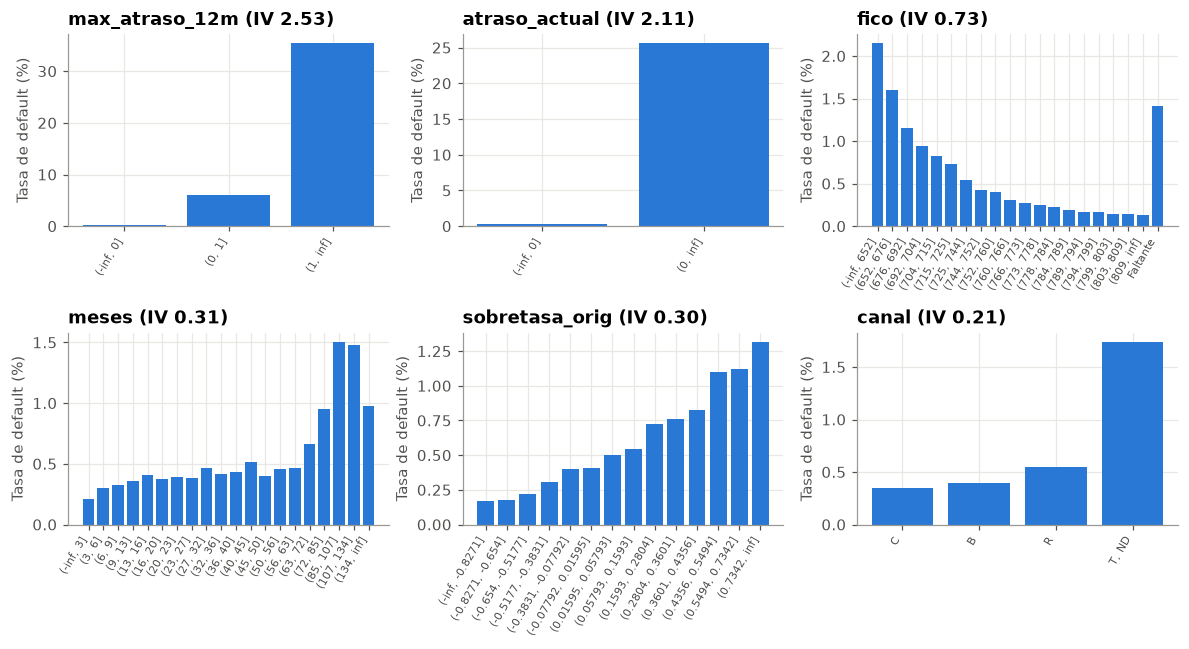

In [26]:
fig, ejes = plt.subplots(2, 3, figsize=(11, 6))
for ax, v in zip(ejes.flat, filtro.loc[finalistas, 'IV'].sort_values(ascending=False).index[:6]):
    tt = tabla_tramos(tramos[v])
    ax.bar(range(len(tt)), tt['tasa (%)'], color=AZUL)
    ax.set_xticks(range(len(tt)))
    ax.set_xticklabels(tt['tramo'], rotation=60, ha='right', fontsize=7)
    ax.set(title=f'{v} (IV {iv(tramos[v]):.2f})', ylabel='Tasa de default (%)')
mostrar(fig, 'tramos_finalistas')

## 7. Modelos: referencia simple, logística y árboles

### Teoría: probabilidad, odds y logit; logística y árboles

Una probabilidad de default de 0.5 % se puede escribir de tres formas:

| Forma | Fórmula | Valor para p = 0.5 % |
|---|---|---|
| Probabilidad | p | 0.005 |
| **Odds** | p ÷ (1 − p) | 0.00503: 1 default por cada 199 que pagan |
| **Logit** | ln(odds) | −5.29 |

**La regresión logística** modela el logit como una suma: *logit = b₀ + b₁ × WoE₁ + b₂ × WoE₂ + …* Cada punto de logit multiplica las odds por *e ≈ 2.72*. Sumar 0.7 al logit las multiplica por 2 y, con probabilidades chicas, casi duplica la PD. Eso es lo que hace la calibración de la sección 9.

**Los árboles con *boosting*** (LightGBM y XGBoost) suman cientos de árboles pequeños, cada uno corrigiendo los errores de los anteriores. Capturan interacciones, como un FICO bajo que solo es grave si además hay atraso. Las **restricciones monótonas** les prohíben aprender relaciones absurdas, por ejemplo que más FICO aumente el riesgo.

In [27]:
j_p = np.array([0.001, 0.005, 0.01, 0.05, 0.20])
j_tabla = pd.DataFrame({'PD': j_p, 'odds': j_p / (1 - j_p), 'logit': logit(j_p)})
j_tabla['PD con logit + 0.7'] = sigmoide(j_tabla['logit'] + 0.7)
j_tabla['multiplicador de la PD'] = j_tabla['PD con logit + 0.7'] / j_tabla['PD']
j_tabla.round(4)

,PD,odds,logit,PD con logit + 0.7,multiplicador de la PD
0,0.001,0.0010,-6.9068,0.0020,2.0117
1,0.005,0.0050,-5.2933,0.0100,2.0036
2,0.010,0.0101,-4.5951,0.0199,1.9935
3,0.050,0.0526,-2.9444,0.0958,1.9166
4,0.200,0.2500,-1.3863,0.3349,1.6743


**Qué muestra el ejemplo.** Sumar 0.7 al logit duplica las odds de todos los créditos. Con PD chicas (0.1 % a 1 %), la PD casi se duplica; con una PD de 20 %, sube menos, porque una probabilidad no puede pasar de 1.

**Errores comunes**

- **Interpretar un coeficiente como "puntos de PD".** Un coeficiente mueve el logit; su efecto en la PD depende de dónde parte el crédito.
- **Elegir el modelo con la muestra de entrenamiento.** Los árboles casi siempre ganan ahí porque memorizan.
- **Elegir la regla de decisión después de ver los resultados.** Por eso la regla de este notebook se fija antes.

---

### Aplicación al proyecto

| Modelo | Idea | A favor | En contra |
|---|---|---|---|
| **Regla simple** | Ordenar por peor atraso de los últimos 12 meses y, dentro de cada grupo, por FICO | Se explica en una frase | No usa el resto de la información |
| **Logística con WoE** | Suma ponderada de los WoE de las finalistas | Transparente, estable y fácil de auditar | Supone efectos aditivos |
| **LightGBM y XGBoost con finalistas** | Muchos árboles pequeños que corrigen los errores de los anteriores | Captura interacciones y no linealidades | Más difícil de explicar y de mantener |
| **LightGBM con todas** | El mismo algoritmo con todas las candidatas | Mide cuánto se pierde al seleccionar | Más variables que vigilar |

Los árboles usan **restricciones monótonas**: si el riesgo debe bajar con el FICO, el modelo no puede aprender lo contrario en ningún tramo. Es una forma de exigir coherencia económica. Para no usar la prueba de desarrollo en el ajuste, la detención temprana usa un 10 % de los créditos de entrenamiento.

**Regla de elección, fijada antes de ver resultados.** Gana el modelo con mayor Gini en la prueba de desarrollo, salvo que uno más simple quede a menos de `TOLERANCIA_GINI`. El orden de simplicidad es: regla, logística, árboles con finalistas y árboles con todas.

In [28]:
def score_regla(d):
    return d['max_atraso_12m'].to_numpy() * 1000 + (900 - d['fico'].fillna(d['fico'].median()).to_numpy())

def matriz_woe(d, cols):
    return pd.DataFrame({v: transformar(d[v], tramos[v]) for v in cols})

ids_val = set(np.random.default_rng(SEMILLA + 1).choice(train.id.unique(), int(train.id.nunique() * 0.1), replace=False))
es_val = train.id.isin(ids_val).to_numpy()

def ajustar_arbol(tipo, cols):
    mono = [0 if (v in CATEGORICAS or v in NO_MONOTONAS) else int(tramos[v]['signo']) for v in cols]
    X, y = train[cols], train.default
    if tipo == 'lightgbm':
        m = LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=500,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, monotone_constraints=mono,
                           random_state=SEMILLA, verbose=-1)
        m.fit(X[~es_val], y[~es_val], eval_set=[(X[es_val], y[es_val])],
              callbacks=[early_stopping(100, verbose=False)])
    else:
        m = XGBClassifier(n_estimators=2000, learning_rate=0.03, max_depth=5, min_child_weight=50, subsample=0.8,
                          colsample_bytree=0.8, tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
                          monotone_constraints={v: c for v, c in zip(cols, mono)}, early_stopping_rounds=100,
                          eval_metric='logloss', random_state=SEMILLA)
        m.fit(X[~es_val], y[~es_val], eval_set=[(X[es_val], y[es_val])], verbose=False)
    return m

modelos = {
    'Regla simple': (None, lambda d: score_regla(d)),
    'Logística WoE': (modelo_log, lambda d: modelo_log.predict_proba(matriz_woe(d, finalistas))[:, 1]),
}
for nombre, tipo, cols in [('LightGBM finalistas', 'lightgbm', finalistas), ('XGBoost finalistas', 'xgboost', finalistas),
                           ('LightGBM todas', 'lightgbm', [v for v in POOL if filtro.loc[v, 'motivo'] in ('', 'IV bajo')])]:
    m = ajustar_arbol(tipo, cols)
    modelos[nombre] = (m, (lambda m_, c_: (lambda d: m_.predict_proba(d[c_])[:, 1]))(m, cols))
punt_test, boot_test = bootstrap(test.default, {k: f(test) for k, (_, f) in modelos.items()}, test.id)
comparacion = pd.DataFrame({
    'Gini test': [punt_test[k][0] for k in modelos], 'Gini IC 95 %': [ic(boot_test[k][:, 0]) for k in modelos],
    'PR AUC test': [punt_test[k][1] for k in modelos], 'PR AUC IC 95 %': [ic(boot_test[k][:, 1]) for k in modelos],
}, index=list(modelos))
mejor = comparacion['Gini test'].idxmax()
ELEGIDO = next(k for k in modelos if comparacion.loc[k, 'Gini test'] >= comparacion.loc[mejor, 'Gini test'] - TOLERANCIA_GINI)
dif = boot_test[mejor][:, 0] - boot_test[ELEGIDO][:, 0]
print(f'Mayor Gini: {mejor} | Elegido por la regla: {ELEGIDO} | Diferencia {comparacion.loc[mejor, "Gini test"] - comparacion.loc[ELEGIDO, "Gini test"]:.3f} (IC {ic(dif)})')
print(f'Tasa de default en test: {pct(test.default.mean())} (el PR AUC de un orden al azar)')
comparacion.round(3)

Mayor Gini: LightGBM todas | Elegido por la regla: Logística WoE | Diferencia 0.011 (IC 0.006 a 0.016)
Tasa de default en test: 0.59 % (el PR AUC de un orden al azar)


,Gini test,Gini IC 95 %,PR AUC test,PR AUC IC 95 %
Regla simple,0.732,0.714 a 0.750,0.209,0.190 a 0.225
Logística WoE,0.804,0.791 a 0.817,0.226,0.208 a 0.245
LightGBM finalistas,0.813,0.800 a 0.825,0.276,0.258 a 0.297
XGBoost finalistas,0.814,0.800 a 0.826,0.285,0.266 a 0.306
LightGBM todas,0.814,0.800 a 0.826,0.277,0.257 a 0.298


**Lectura.**

- **La regla elige la logística.** El modelo con mayor Gini es LightGBM con todas las variables (0.814), y la logística queda a 0.011 (0.804). La diferencia es real, porque su intervalo (0.006 a 0.016) excluye el cero, pero es menor que la tolerancia de 0.02. Preferimos ganar transparencia a cambio de una centésima de Gini.
- **Los árboles ordenan mejor dentro del grupo de alto riesgo.** Su PR AUC (0.276 a 0.285) supera al de la logística (0.226). Con eventos raros, el PR AUC se decide entre los créditos con atraso, donde la interacción entre variables pesa más.
- **La regla simple** (peor atraso y FICO) logra 0.732 de Gini: buena para una frase, pero 0.07 por debajo de la logística.
- **La tasa de default de la prueba es 0.59 %,** así que un PR AUC de 0.226 es unas 38 veces lo que lograría un orden al azar.

## 8. Desempeño fuera de tiempo

### Teoría: Gini, curva ROC, PR AUC y lift

**De un score a una decisión.** El modelo da a cada crédito un score de riesgo. Si fijamos un punto de corte y marcamos como riesgosos a los que lo superan, se pueden contar tres cosas:

- **Recall** (tasa de verdaderos positivos): qué parte de los defaults quedó marcada.
- **Tasa de falsos positivos:** qué parte de los que pagan quedó marcada por error.
- **Precisión:** de los marcados, qué parte incumple de verdad.

**Curva ROC, AUC y Gini.** La curva ROC dibuja el recall frente a la tasa de falsos positivos para todos los cortes posibles. El área bajo esa curva (AUC) es **la probabilidad de que, al tomar un default y un no default al azar, el default tenga el score más riesgoso**. El Gini es la misma información en otra escala: *Gini = 2 × AUC − 1*, donde 0 es azar y 1 es orden perfecto. No depende de la tasa de default.

**Curva precisión–recall y PR AUC.** Esta curva dibuja la precisión frente al recall al recorrer la lista de mayor a menor riesgo. Su área es el **PR AUC**, y aquí se estima con la **precisión promedio (AP)**: el promedio de la precisión en la posición de cada default de la lista. Hay tres cosas que la distinguen del Gini:

1. **Su valor al azar es la tasa de default (π),** no 0.5. Con π = 0.5 %, un orden al azar logra un PR AUC de 0.005. Por eso se reporta **PR AUC − π**, la mejora sobre esa línea base.
2. **Sí depende de la tasa de default.** El mismo modelo tiene un PR AUC mucho menor en una cartera con menos eventos.
3. **Hay que nombrar el método de cálculo.** La precisión promedio (AP) suma escalones; el área trapezoidal une los puntos con rectas. Dan valores distintos, así que no se deben mezclar al comparar modelos.

**Lift y recall a un porcentaje fijo.** Para el 5 % más riesgoso, el lift es *precisión en ese 5 % ÷ π* (1 es azar) y el recall es la parte de los defaults que cae ahí (5 % es azar).

**Ejemplo mínimo.** Ocho créditos, dos de ellos con default. Contamos a mano los 2 × 6 = 12 pares default–no default para el AUC, y recorremos la lista ordenada para la precisión promedio.

In [29]:
from sklearn.metrics import average_precision_score, roc_auc_score

j_y = np.array([1, 1, 0, 0, 0, 0, 0, 0])
j_s = np.array([0.90, 0.40, 0.70, 0.30, 0.20, 0.15, 0.10, 0.05])
j_pares = [(a, b) for a in j_s[j_y == 1] for b in j_s[j_y == 0]]
j_bien = sum(a > b for a, b in j_pares)
print(f'Pares bien ordenados: {j_bien} de {len(j_pares)} → AUC = {j_bien / len(j_pares):.3f}, Gini = {2 * j_bien / len(j_pares) - 1:.3f}')

j_orden = np.argsort(-j_s)
j_lista = pd.DataFrame({'posición': np.arange(1, 9), 'score': j_s[j_orden], 'default': j_y[j_orden]})
j_lista['defaults acumulados'] = j_lista['default'].cumsum()
j_lista['precisión hasta aquí'] = j_lista['defaults acumulados'] / j_lista['posición']
display(j_lista.round(3))
j_ap = j_lista.loc[j_lista['default'] == 1, 'precisión hasta aquí'].mean()
print(f'Precisión promedio en la posición de cada default: {j_ap:.3f} | scikit-learn: {average_precision_score(j_y, j_s):.3f} '
      f'| línea base π = {j_y.mean():.3f} | PR AUC − π = {j_ap - j_y.mean():.3f}')

Pares bien ordenados: 11 de 12 → AUC = 0.917, Gini = 0.833


,posición,score,default,defaults acumulados,precisión hasta aquí
0,1,0.90,1,1,1.000
1,2,0.70,0,1,0.500
2,3,0.40,1,2,0.667
3,4,0.30,0,2,0.500
4,5,0.20,0,2,0.400
5,6,0.15,0,2,0.333
6,7,0.10,0,2,0.286
7,8,0.05,0,2,0.250


Precisión promedio en la posición de cada default: 0.833 | scikit-learn: 0.833 | línea base π = 0.250 | PR AUC − π = 0.583


**Qué muestra el ejemplo.** El AUC es 11 de 12 pares (0.917) y el Gini, 0.833. Para el PR AUC, el primer default aparece en la posición 1 (precisión 1/1) y el segundo en la posición 3 (precisión 2/3), así que la precisión promedio es (1 + 0.667) ÷ 2 = 0.833. Su línea base es la tasa de default del ejemplo, 0.25.

**Por qué con eventos raros se reportan los dos.** En la simulación siguiente, el mismo modelo se aplica a una cartera con 20 % de defaults y a otra con 0.5 %.

In [30]:
j_rng = np.random.default_rng(SEMILLA)
j_filas = []
for tasa in (0.20, 0.005):
    j_yy = (j_rng.random(400_000) < tasa).astype(int)
    j_ss = j_rng.normal(loc=1.8 * j_yy)                        # mismo modelo: los defaults tienen score más alto
    j_top = np.argsort(-j_ss)[:int(0.05 * len(j_ss))]          # el 5 % más riesgoso
    j_pr = average_precision_score(j_yy, j_ss)
    j_filas.append({'tasa de default (π)': tasa, 'Gini': 2 * roc_auc_score(j_yy, j_ss) - 1, 'PR AUC': j_pr,
                    'PR AUC − π': j_pr - tasa, 'precisión en el 5 % más riesgoso': j_yy[j_top].mean(),
                    'lift al 5 %': j_yy[j_top].mean() / tasa})
pd.DataFrame(j_filas).round(3)

,tasa de default (π),Gini,PR AUC,PR AUC − π,precisión en el 5 % más riesgoso,lift al 5 %
0,0.200,0.798,0.733,0.533,0.910,4.551
1,0.005,0.794,0.131,0.126,0.055,11.060


**Qué muestra la simulación.** El Gini es prácticamente el mismo en las dos carteras, porque no depende de la tasa de default. El PR AUC, en cambio, cae mucho con 0.5 % de defaults: aunque el modelo ordena igual de bien, en el grupo más riesgoso la mayoría de los créditos no incumple. El Gini dice qué tan bien ordena; el PR AUC, el lift y la precisión dicen qué tan útil es la lista cuando el evento es raro. Por eso se reportan juntos.

**Errores comunes**

- **Comparar el PR AUC entre carteras o años con tasas de default distintas.** Hay que compararlo contra su propia línea base (PR AUC − π).
- **Mezclar la precisión promedio (AP) y el área trapezoidal** entre modelos. Son estimadores distintos; hay que usar uno y nombrarlo.
- **Mirar solo el Gini con eventos raros.** Un Gini alto no garantiza que el grupo marcado tenga muchos defaults.

> **Pruébalo.** En el ejemplo de ocho créditos, cambia el score del segundo default de 0.40 a 0.80. ¿Cómo cambian el AUC y la precisión promedio?

---

### Aplicación al proyecto

Ahora sí miramos la muestra OOT, con todos los modelos por transparencia. La que cuenta es la fila del modelo elegido. En la tabla por año agregamos el **PSI del score**: compara la distribución del score de cada año con la del entrenamiento, usando sus deciles. Es el primer indicador que se vigila en producción, porque no necesita esperar 12 meses a que maduren los defaults.

### Cómo se mide el desempeño con eventos raros

| Métrica | Qué responde | Cómo leerla |
|---|---|---|
| **Gini** | ¿Ordena bien a un default frente a un no default? | No depende de la tasa de default |
| **PR AUC** | ¿Qué precisión mantiene al recorrer la lista de mayor a menor riesgo? | Se estima con la precisión promedio (AP). Su valor al azar es la tasa de default, así que se compara contra ella (`PR AUC − π`) |
| **Lift al 5 %** | ¿Cuántas veces más defaults hay en el 5 % más riesgoso? | 1 es azar |
| **Recall al 5 %** | ¿Qué parte de todos los defaults cae en ese 5 %? | 5 % es azar |

Con una tasa de 0.5 %, el Gini puede verse muy alto aunque la precisión sea baja: en el grupo más riesgoso, la mayoría de los créditos tampoco incumple. Por eso reportamos ambas.

In [31]:
scores_oot = {k: f(oot) for k, (_, f) in modelos.items()}
punt_oot, boot_oot = bootstrap(oot.default, scores_oot, oot.id)
pi_oot = oot.default.mean()

def lift_recall(y, s, q=0.05):
    orden = np.argsort(-s, kind='mergesort')[:int(len(s) * q)]
    capt = y[orden].sum()
    return capt / len(orden) / y.mean(), capt / y.sum()

y_oot = oot.default.to_numpy()
tabla_oot = pd.DataFrame({
    'Gini': [punt_oot[k][0] for k in modelos], 'Gini IC 95 %': [ic(boot_oot[k][:, 0]) for k in modelos],
    'PR AUC': [punt_oot[k][1] for k in modelos], 'PR AUC − π': [punt_oot[k][1] - pi_oot for k in modelos],
    'Lift 5 %': [lift_recall(y_oot, scores_oot[k])[0] for k in modelos],
    'Recall 5 %': [lift_recall(y_oot, scores_oot[k])[1] for k in modelos],
}, index=list(modelos))
print(f'OOT: {len(oot):,} filas, {int(y_oot.sum()):,} defaults, tasa {pct(pi_oot)}')
for k in modelos:
    if k != ELEGIDO:
        print(f'{k} − {ELEGIDO}: ΔGini {punt_oot[k][0] - punt_oot[ELEGIDO][0]:+.3f} (IC {ic(boot_oot[k][:, 0] - boot_oot[ELEGIDO][:, 0])})')
tabla_oot.round(3)

OOT: 2,034,470 filas, 11,209 defaults, tasa 0.55 %
Regla simple − Logística WoE: ΔGini -0.008 (IC -0.013 a -0.002)
LightGBM finalistas − Logística WoE: ΔGini +0.011 (IC 0.009 a 0.014)
XGBoost finalistas − Logística WoE: ΔGini +0.010 (IC 0.008 a 0.012)
LightGBM todas − Logística WoE: ΔGini +0.015 (IC 0.013 a 0.018)


,Gini,Gini IC 95 %,PR AUC,PR AUC − π,Lift 5 %,Recall 5 %
Regla simple,0.768,0.761 a 0.775,0.157,0.151,13.502,0.675
Logística WoE,0.776,0.769 a 0.783,0.183,0.178,13.489,0.674
LightGBM finalistas,0.787,0.781 a 0.795,0.191,0.186,13.520,0.676
XGBoost finalistas,0.786,0.779 a 0.793,0.189,0.184,13.512,0.676
LightGBM todas,0.791,0.785 a 0.798,0.197,0.191,13.545,0.677


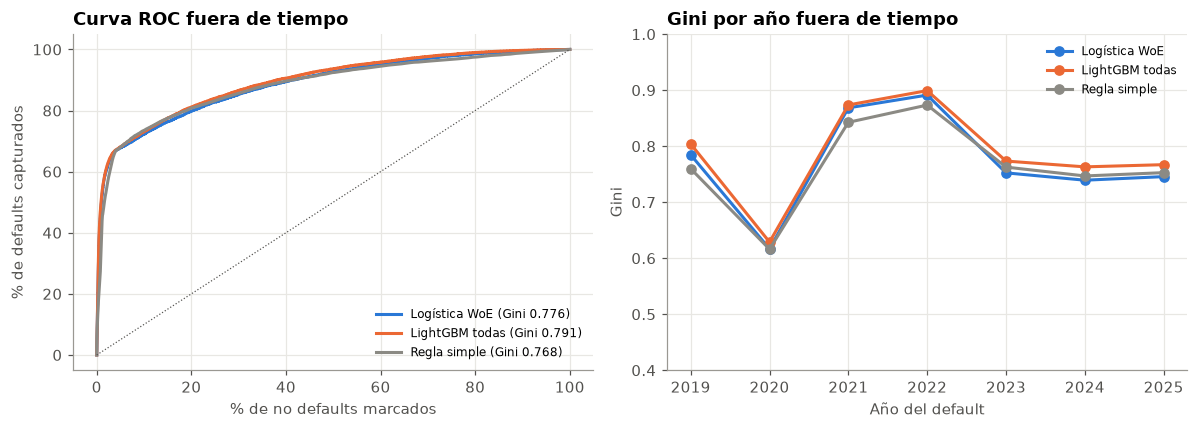

,créditos,defaults,tasa (%),PSI del score,Gini Logística WoE,Gini Regla simple,Gini LightGBM todas
año del default,,,,,,,
2019,309128,1257,0.407,0.017,0.785,0.760,0.804
2020,316777,1223,0.386,0.026,0.617,0.616,0.629
2021,275865,1575,0.571,0.029,0.868,0.843,0.874
2022,247288,1796,0.726,0.011,0.891,0.873,0.899
2023,266328,1364,0.512,0.025,0.752,0.763,0.773
2024,297110,1873,0.630,0.043,0.739,0.747,0.763
2025,321974,2121,0.659,0.049,0.746,0.753,0.767


In [32]:
s_train = modelos[ELEGIDO][1](train)
deciles = np.unique(np.quantile(s_train, np.linspace(0, 1, 11)[1:-1]))
def psi_score(a, b):
    p_ = np.bincount(np.searchsorted(deciles, a), minlength=len(deciles) + 1) / len(a)
    q_ = np.bincount(np.searchsorted(deciles, b), minlength=len(deciles) + 1) / len(b)
    p_, q_ = np.clip(p_, 1e-6, None), np.clip(q_, 1e-6, None)
    return float(np.sum((p_ - q_) * np.log(p_ / q_)))

por_anio = []
for c in range(CORTES_OOT[0], CORTES_OOT[1] + 1):
    m = (oot.corte == c).to_numpy()
    fila = {'año del default': c + 1, 'créditos': int(m.sum()), 'defaults': int(y_oot[m].sum()), 'tasa (%)': y_oot[m].mean() * 100,
            'PSI del score': psi_score(s_train, scores_oot[ELEGIDO][m])}
    for k in [ELEGIDO, 'Regla simple', 'LightGBM todas']:
        fila[f'Gini {k}'] = 2 * roc_auc_score(y_oot[m], scores_oot[k][m]) - 1
    por_anio.append(fila)
por_anio = pd.DataFrame(por_anio).set_index('año del default')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for k, col in [(ELEGIDO, AZUL), ('LightGBM todas', NARANJA), ('Regla simple', GRIS)]:
    fpr, tpr, _ = roc_curve(y_oot, scores_oot[k])
    a1.plot(fpr * 100, tpr * 100, color=col, label=f'{k} (Gini {punt_oot[k][0]:.3f})')
a1.plot([0, 100], [0, 100], color=TINTA, linewidth=0.8, linestyle=':')
a1.set(title='Curva ROC fuera de tiempo', xlabel='% de no defaults marcados', ylabel='% de defaults capturados')
a1.legend(loc='lower right', fontsize=8)
for k, col in [(ELEGIDO, AZUL), ('LightGBM todas', NARANJA), ('Regla simple', GRIS)]:
    a2.plot(por_anio.index, por_anio[f'Gini {k}'], marker='o', color=col, label=k)
a2.set(title='Gini por año fuera de tiempo', xlabel='Año del default', ylabel='Gini', ylim=(0.4, 1))
a2.legend(fontsize=8)
mostrar(fig, 'desempeno_oot')
por_anio.round(3)

**Lectura.**

- **La logística logra un Gini fuera de tiempo de 0.776** (0.769 a 0.783), 0.028 menos que en la prueba de desarrollo. Es una caída esperada al pasar a años que el modelo no vio.
- **LightGBM con todas sigue arriba por 0.015** (0.013 a 0.018), una brecha similar a la del desarrollo. Ningún modelo se degradó de forma desproporcionada.
- **La regla simple queda a solo 0.008 de la logística.** El historial de atraso explica la mayor parte del orden; las demás variables afinan el orden entre los créditos al día.
- **El PR AUC es 0.183 con una tasa de 0.55 %.** Ordena 33 veces mejor que el azar, pero la precisión sigue siendo baja: incluso en el grupo de mayor riesgo, la mayoría de los créditos no incumple.
- **El lift y el recall al 5 % son casi iguales en todos los modelos** (13.5 y 67 %). Ese 5 % lo forman sobre todo los créditos con atraso reciente, y todos los modelos los ponen primero. Las diferencias aparecen más abajo en el orden.
- **El año 2020 es el más difícil (Gini 0.62).** Los defaults de 2020 vinieron de un choque repentino que el historial a diciembre de 2019 no anticipaba. En 2021 y 2022 el Gini sube a 0.87–0.89, porque el atraso durante el *forbearance* sí anticipó quién incumpliría al terminar el alivio. Desde 2023 se estabiliza entre 0.74 y 0.75.
- **El PSI del score se mantiene por debajo de 0.05 todos los años:** la población no se movió lo suficiente como para encender una alerta.

## 9. Calibración con pocos defaults

### Teoría: ordenar no es calibrar

Un modelo hace dos trabajos distintos:

- **Ordenar:** poner a los riesgosos arriba. Se mide con el Gini y, con eventos raros, también con el PR AUC.
- **Calibrar:** que la PD coincida con la tasa observada. Si a mil créditos les damos 2 %, deberían incumplir unos 20.

Un modelo puede ordenar perfecto y estar mal calibrado. Basta con multiplicar todas las PD por dos: el orden no cambia y el nivel queda mal.

**PIT y TTC.** Una PD *point in time* (PIT) sigue al momento: baja en años buenos y sube en crisis. Una PD *through the cycle* (TTC) es el promedio de largo plazo, años buenos y malos incluidos. Para capital se busca una PD TTC, para que el capital no caiga justo antes de una crisis.

**Calibrar con un desplazamiento en logit.** Se suma la misma constante al logit de todos los créditos. El orden se mantiene y el promedio se mueve hasta la tendencia central.

**Ejemplo mínimo.** Cinco créditos con PD del modelo, que queremos llevar a un promedio de 2 %.

In [33]:
from scipy.optimize import brentq as j_brentq

j_pd = np.array([0.002, 0.005, 0.008, 0.015, 0.03])
j_delta = j_brentq(lambda d: sigmoide(logit(j_pd) + d).mean() - 0.02, -5, 5)
j_cal = sigmoide(logit(j_pd) + j_delta)
display(pd.DataFrame({'PD del modelo': j_pd, 'PD calibrada': j_cal, 'orden antes': j_pd.argsort().argsort() + 1,
                      'orden después': j_cal.argsort().argsort() + 1}).round(4))
print(f'Desplazamiento en logit: {j_delta:+.3f} | promedio antes {j_pd.mean():.2%}, después {j_cal.mean():.2%}')
print(f'Piso de Jeffreys con 0 defaults en 2,000 créditos: {(0 + 0.5) / (2_000 + 1):.4%}')

,PD del modelo,PD calibrada,orden antes,orden después
0,0.002,0.0034,1,1
1,0.005,0.0084,2,2
2,0.008,0.0134,3,3
3,0.015,0.0251,4,4
4,0.030,0.0497,5,5


Desplazamiento en logit: +0.525 | promedio antes 1.20%, después 2.00%
Piso de Jeffreys con 0 defaults en 2,000 créditos: 0.0250%


**Qué muestra el ejemplo.** Todas las PD suben, el orden es idéntico y el promedio llega al 2 % buscado. La última línea muestra el **piso de Jeffreys**: un grado sin defaults recibe una PD pequeña, pero no cero.

**Margen de conservadurismo (MoC).** La tendencia central se estima con pocos años, y con otros años saldría distinta. El *bootstrap* de años remuestrea los años del ciclo con reemplazo y recalcula la estimación miles de veces. El margen es la distancia entre la estimación y un percentil alto de esas réplicas.

**Errores comunes**

- **Calibrar con los años del desarrollo.** Si fueron años buenos, la PD subestimará cualquier crisis.
- **Confundir una PD TTC con una PD de estrés.** La TTC es un promedio; en un año malo, lo observado la supera.
- **Asignar PD cero a un grado sin defaults.** Cero observados no significa riesgo cero.

---

### Aplicación al proyecto

Un modelo puede ordenar bien y dar probabilidades equivocadas. El modelo se entrenó con 2013–2017, años buenos con una tasa cercana al 0.5 %, así que sus probabilidades reflejan esos años. Si las usáramos tal cual, la PD estaría **subestimada en cualquier año malo**. La calibración tiene cinco pasos, que siguen la guía de modelamiento:

1. **Tendencia central.** Fijar la tasa de default de largo plazo con un período que incluya la crisis.
2. **Desplazamiento en logit.** Mover todas las probabilidades por igual, en escala logit, hasta que su promedio a lo largo del ciclo coincida con la tendencia central. Esto no cambia el orden.
3. **Escala maestra.** Agrupar los créditos en grados con fronteras de PD fijas.
4. **Mejor estimación por grado.** Usar la tasa observada promedio del ciclo en cada grado, y revisar los grados con pocos defaults con Pluto–Tasche y con una actualización bayesiana.
5. **Margen de conservadurismo.** Sumar la incertidumbre de la estimación y aplicar el piso regulatorio.

### Paso 1. La tendencia central

Aplicamos el modelo elegido a todas las cohortes del ciclo (2003–2017) y comparamos, año por año, la tasa observada con la PD promedio del modelo. La tendencia central es el **promedio simple de las tasas anuales**: cada año pesa lo mismo, sea bueno o malo. Un promedio ponderado por créditos daría más peso a los años con más cartera, que no tienen por qué ser representativos del ciclo.

¿Por qué desde 2003? La muestra empieza con créditos originados en 1999, así que en los primeros cortes la cartera solo tiene créditos de 1 a 3 años de antigüedad. Hacia 2003 ya se parece a una cartera madura. La sensibilidad a esta decisión está en la tabla siguiente.

In [34]:
f_elegido = modelos[ELEGIDO][1]
hist = datos[datos.corte.between(min(CORTES_CICLO[0], 2000), CORTES_OOT[1])].reset_index(drop=True)
hist['pd_bruta'] = f_elegido(hist) if ELEGIDO != 'Regla simple' else np.nan
assert ELEGIDO != 'Regla simple', 'La calibración requiere un modelo que entregue probabilidades'
en_ciclo = hist.corte.between(*CORTES_CICLO)
por_corte = hist[en_ciclo].groupby('corte').agg(tasa=('default', 'mean'), pd_bruta=('pd_bruta', 'mean'), n=('default', 'size'))
TENDENCIA_CENTRAL = por_corte['tasa'].mean()

def desplazamiento(objetivo, d=hist[en_ciclo]):
    lp = logit(d['pd_bruta'].to_numpy()); cortes_ = d['corte'].to_numpy()
    def brecha(delta):
        return pd.Series(sigmoide(lp + delta)).groupby(cortes_).mean().mean() - objetivo
    return brentq(brecha, -5, 5)

DELTA = desplazamiento(TENDENCIA_CENTRAL)
hist['pd_ttc'] = sigmoide(logit(hist['pd_bruta']) + DELTA)

def tc(desde, hasta, excluir=(), ponderar=False):
    t = hist[hist.corte.between(desde, hasta) & ~hist.corte.isin(excluir)].groupby('corte')['default'].agg(['mean', 'size'])
    return np.average(t['mean'], weights=t['size']) if ponderar else t['mean'].mean()

sens_tc = pd.DataFrame({'tendencia central': [
    TENDENCIA_CENTRAL, tc(2000, CORTES_CICLO[1]), tc(2005, CORTES_CICLO[1]), tc(*CORTES_CICLO, ponderar=True),
    tc(CORTES_CICLO[0], CORTES_OOT[1]), tc(CORTES_CICLO[0], CORTES_OOT[1], excluir=(2019, 2020))]},
    index=['Elegida: 2003–2017, promedio simple', 'Desde 2000', 'Desde 2005', '2003–2017 ponderado por créditos',
           '2003–2024 (incluye OOT)', '2003–2024 sin años COVID'])
sens_tc['tendencia central'] = sens_tc['tendencia central'].map(pct)
print(f'Tasa promedio del desarrollo: {pct(train.default.mean())} | Tendencia central: {pct(TENDENCIA_CENTRAL)} | '
      f'Desplazamiento en logit: {DELTA:+.3f}')
sens_tc

Tasa promedio del desarrollo: 0.57 % | Tendencia central: 1.18 % | Desplazamiento en logit: +0.708


,tendencia central
"Elegida: 2003–2017, promedio simple",1.18 %
Desde 2000,1.13 %
Desde 2005,1.25 %
2003–2017 ponderado por créditos,1.21 %
2003–2024 (incluye OOT),0.98 %
2003–2024 sin años COVID,1.03 %


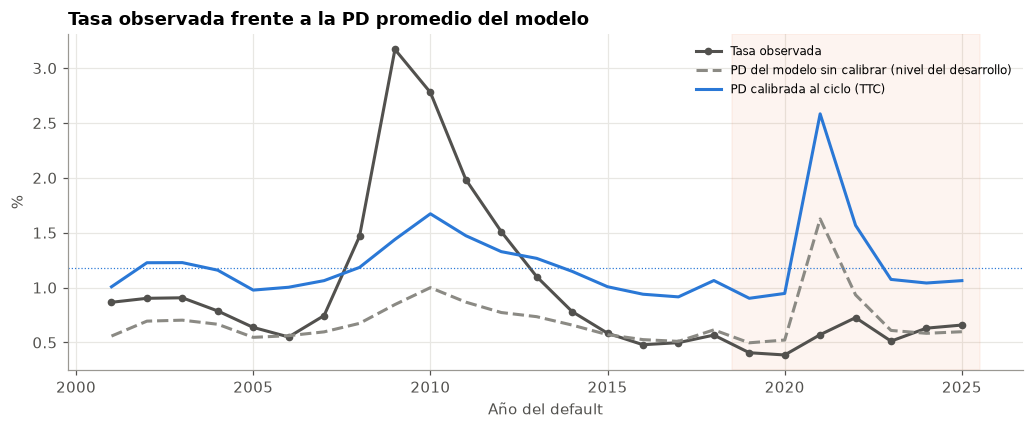

In [35]:
serie = hist.groupby('corte').agg(tasa=('default', 'mean'), pd_bruta=('pd_bruta', 'mean'), pd_ttc=('pd_ttc', 'mean'))
fig, ax = plt.subplots(figsize=(9.5, 4))
x = serie.index + 1
ax.plot(x, serie['tasa'] * 100, color=TINTA, marker='o', markersize=4, label='Tasa observada')
ax.plot(x, serie['pd_bruta'] * 100, color=GRIS, linestyle='--', label='PD del modelo sin calibrar (nivel del desarrollo)')
ax.plot(x, serie['pd_ttc'] * 100, color=AZUL, label='PD calibrada al ciclo (TTC)')
ax.axhline(TENDENCIA_CENTRAL * 100, color=AZUL, linewidth=0.8, linestyle=':')
ax.axvspan(CORTES_OOT[0] + 0.5, CORTES_OOT[1] + 1.5, color=NARANJA, alpha=0.07)
ax.set(title='Tasa observada frente a la PD promedio del modelo', xlabel='Año del default', ylabel='%')
ax.legend(fontsize=8)
mostrar(fig, 'calibracion_ciclo')

**Lectura.**

- **La tendencia central (1.18 %) duplica la tasa del desarrollo (0.57 %).** El desplazamiento en logit es +0.708, que equivale a multiplicar por 2 las chances (`p / (1 − p)`) de todos los créditos.
- **La elección es razonablemente estable.** Según el período y la ponderación, la tendencia central va de 1.13 % a 1.25 %. Si incluyéramos los años fuera de tiempo, bajaría a 0.98 %. No lo hacemos para que la prueba siga limpia, pero una recalibración en producción debería incorporarlos.
- **El gráfico muestra qué hace la calibración TTC.** La PD calibrada se mueve poco, mientras que la tasa observada sube a 3.17 % en 2009 y baja a 0.4 % en años buenos. **Por diseño, una PD TTC no sigue el ciclo:** queda por debajo de lo observado en la crisis y por encima en los años buenos.
- **El modelo sin calibrar subestima la crisis por un factor de más de 3.** En 2009 predice menos de 1 %, frente a 3.17 % observado.
- **El salto de 2021 tiene una causa clara.** A diciembre de 2020, muchos créditos tenían atrasos acumulados durante el *forbearance*, y el modelo los trata como atraso real. La PD sube para todos ellos, aunque la tasa observada fue 0.57 %. El error es conservador y dura un año, pero muestra un límite del modelo ante una situación que no vio en el desarrollo.

### Pasos 3 y 4. Escala maestra y mejor estimación por grado

Cada grado cubre un rango de PD que duplica al anterior, salvo el primero, que reúne todo lo que está por debajo de 0.1 %. Un primer grado más fino (por debajo de 0.05 %) tendría apenas el 0.1 % de la cartera y ningún default en 15 años: la guía recomienda unir grados vecinos con poco soporte. Para cada grado calculamos, con los cortes del ciclo:

- la **tasa observada de cada año** y su promedio simple, que es la **mejor estimación (BE)** del grado;
- una **regresión isotónica** sobre esas tasas, que garantiza que la PD nunca baje al pasar a un grado peor;
- un **piso de Jeffreys**, `(defaults + 0.5) / (créditos + 1)`, para que un grado sin defaults no reciba PD cero. Cero defaults observados no significa riesgo cero.

### Paso 5. Margen de conservadurismo

En una PD a un año, la mayor fuente de incertidumbre no es el número de créditos, sino **cuántos años del ciclo hemos visto**. Con 15 años, la crisis pesa 3 o 4; con otros 15 años podría pesar distinto. Por eso medimos el error de estimación con un ***bootstrap* de años**: remuestreamos los 15 años del ciclo con reemplazo, recalculamos la BE de cada grado y tomamos el percentil 90. El margen es la diferencia entre ese percentil y la BE.

**PD final** = máximo entre (BE + margen) y el piso de 0.05 %.

In [36]:
etiquetas_g = [f'G{i}' for i in range(1, len(LIMITES_GRADOS))]
def grado(p):
    return np.clip(np.searchsorted(LIMITES_GRADOS, p, side='right') - 1, 0, len(etiquetas_g) - 1)
hist['grado'] = grado(hist['pd_ttc'].to_numpy())
ciclo = hist[en_ciclo]
n_gt = ciclo.pivot_table(index='grado', columns='corte', values='default', aggfunc='size', fill_value=0)
d_gt = ciclo.pivot_table(index='grado', columns='corte', values='default', aggfunc='sum', fill_value=0)
tasa_gt = d_gt / n_gt.replace(0, np.nan)

def mejor_estimacion(tasas, n, d):
    # Promedio simple de las tasas anuales, monotónico, con piso de Jeffreys para grados con pocos defaults
    be = tasas.mean(axis=1).fillna(0).to_numpy()
    iso = IsotonicRegression(increasing=True).fit(np.arange(len(be)), be, sample_weight=n.sum(axis=1).to_numpy())
    jeffreys = (d.sum(axis=1).to_numpy() + 0.5) / (n.sum(axis=1).to_numpy() + 1)
    return np.maximum.accumulate(np.maximum(iso.predict(np.arange(len(be))), jeffreys))

BE = mejor_estimacion(tasa_gt, n_gt, d_gt)
rng = np.random.default_rng(SEMILLA)
anios_ciclo = tasa_gt.columns.to_numpy()
boot_be = []
for _ in range(2000):
    elegidos = rng.choice(anios_ciclo, len(anios_ciclo))
    boot_be.append(mejor_estimacion(tasa_gt[elegidos], n_gt[elegidos], d_gt[elegidos]))
boot_be = np.array(boot_be)
MOC = np.maximum(np.quantile(boot_be, CUANTIL_MOC, axis=0) - BE, 0)
PD_FINAL = np.maximum(BE + MOC, PD_PISO)

escala = pd.DataFrame({
    'rango de PD TTC': [f'{pct(LIMITES_GRADOS[i], 2)} a {pct(LIMITES_GRADOS[i + 1], 2)}' for i in range(len(etiquetas_g))],
}, index=etiquetas_g)
escala = escala.iloc[n_gt.index]
escala['créditos-año'] = n_gt.sum(axis=1).to_numpy()
escala['% de la cartera'] = escala['créditos-año'] / escala['créditos-año'].sum() * 100
escala['defaults'] = d_gt.sum(axis=1).to_numpy()
escala['años con 0 defaults'] = (d_gt == 0).sum(axis=1).to_numpy()
escala['tasa mínima anual (%)'] = tasa_gt.min(axis=1).to_numpy() * 100
escala['tasa máxima anual (%)'] = tasa_gt.max(axis=1).to_numpy() * 100
escala['BE (%)'] = BE * 100
escala['MoC (pp)'] = MOC * 100
escala['PD final (%)'] = PD_FINAL * 100
escala.round(3)

,rango de PD TTC,créditos-año,% de la cartera,defaults,años con 0 defaults,tasa mínima anual (%),tasa máxima anual (%),BE (%),MoC (pp),PD final (%)
G1,0.00 % a 0.10 %,104965,3.183,8,9,0.000,0.039,0.008,0.004,0.050
G2,0.10 % a 0.20 %,543819,16.489,280,0,0.017,0.207,0.052,0.018,0.070
G3,0.20 % a 0.40 %,1108760,33.618,2644,0,0.065,0.808,0.239,0.082,0.320
G4,0.40 % a 0.80 %,989061,29.989,8073,0,0.240,2.356,0.816,0.243,1.060
G5,0.80 % a 1.60 %,373008,11.310,6603,0,0.505,5.021,1.770,0.466,2.236
G6,1.60 % a 3.20 %,58553,1.775,1539,0,1.032,7.425,2.755,0.619,3.373
G7,3.20 % a 6.40 %,35107,1.064,1719,0,2.343,10.220,4.898,0.862,5.760
G8,6.40 % a 12.80 %,29111,0.883,2236,0,3.891,18.837,7.682,1.495,9.178
G9,12.80 % a 25.60 %,21278,0.645,3753,0,8.289,32.630,17.639,2.707,20.346
G10,25.60 % a 100.00 %,34467,1.045,13119,0,26.034,55.190,38.063,3.656,41.719


**Lectura.**

- **La escala tiene 10 grados con PD monotónica,** de 0.008 % a 38 %. G3 y G4 concentran el 64 % de la cartera del ciclo; los grados G6 a G10, menos del 6 %.
- **G1 es un grado de bajo default.** Tiene 104,965 créditos-año y solo 8 defaults en 15 años, y en 9 de esos años no hubo ninguno. Su BE es 0.008 % y el piso de 0.05 % define su PD final. En G2 (BE 0.052 %), el margen lleva la PD a 0.070 %.
- **El margen crece con el riesgo en puntos, pero baja en proporción.** En G2 a G4 suma entre 30 % y 35 % a la BE (por ejemplo, de 0.239 % a 0.320 % en G3). En G10 suma 10 % (de 38.1 % a 41.7 %). Los grados con pocos defaults son los que más dependen de qué años tocaron.
- **La PD final no es una PD de estrés.** El peor año observado supera a la PD final en todos los grados salvo G1. En G4, por ejemplo, el peor año fue 2.36 % y la PD final es 1.06 %. Es lo esperado en una PD TTC: un promedio del ciclo más un margen por incertidumbre. El estrés se mide aparte, por ejemplo con la fórmula de capital (sección 13).

### Grados con pocos defaults: Pluto–Tasche y actualización bayesiana

En los mejores grados, un año entero puede pasar con muy pocos defaults, o ninguno. Una tasa observada de cero no significa PD cero. Dos métodos ayudan a poner un límite razonable:

**Pluto–Tasche.** Supone que el orden de los grados es correcto, así que la PD del grado 1 no puede ser mayor que la del grado 2, ni esta que la del grado 3. Para estimar la cota del grado *k* se juntan sus créditos con los de todos los grados peores, y se busca la PD más alta compatible, con el nivel de confianza elegido, con haber visto tan pocos defaults. Así, los grados buenos se apoyan en la evidencia de los peores.

- **Con independencia:** la cota es el cuantil de una distribución Beta (el método exacto de Clopper–Pearson).
- **Con correlación:** los defaults de un mismo año no son independientes, porque un mal año afecta a todos. Usamos el modelo de un factor de Vasicek con ρ = 0.15: en cada año se sortea un factor común que sube o baja la PD de todos los créditos a la vez. La cota sube, porque pocos defaults pueden deberse a años buenos.

**Actualización bayesiana.** El *prior* sale de los años anteriores al desarrollo (2003–2012), con un peso equivalente a un año promedio de créditos. Se actualiza con los defaults del desarrollo (2013–2017). Así no se usan los mismos datos dos veces.

Usamos la ventana de desarrollo, que es la situación típica de un banco: cinco años, con pocos defaults en los mejores grados.

In [37]:
desarrollo_h = hist[hist.corte.between(*CORTES_DESARROLLO)]
n_dev = desarrollo_h.pivot_table(index='grado', columns='corte', values='default', aggfunc='size', fill_value=0).reindex(n_gt.index, fill_value=0)
d_dev = desarrollo_h.pivot_table(index='grado', columns='corte', values='default', aggfunc='sum', fill_value=0).reindex(n_gt.index, fill_value=0)
z_gh, w_gh = np.polynomial.hermite_e.hermegauss(40)
w_gh = w_gh / w_gh.sum()

def pt_independiente(n, d, conf=CONFIANZA_PT):
    return stats.beta.ppf(conf, d + 1, n - d)

def pt_correlacionado(n_anios, d, conf=CONFIANZA_PT, rho=RHO, sims=20000, semilla=SEMILLA):
    # P(D <= d | p) con un factor común por año; D condicional ~ Poisson(sum n_t p(z_t))
    z = np.random.default_rng(semilla).standard_normal((sims, len(n_anios)))
    def prob(p):
        pz = stats.norm.cdf((stats.norm.ppf(p) - np.sqrt(rho) * z) / np.sqrt(1 - rho))
        return stats.poisson.cdf(d, pz @ n_anios).mean() - (1 - conf)
    return brentq(prob, 1e-7, 0.5)

pre = hist[hist.corte.between(CORTES_CICLO[0], CORTES_DESARROLLO[0] - 1)]
pre_t = pre.groupby('grado')['default'].agg(['mean', 'size']).reindex(n_gt.index)
anios_pre = pre.corte.nunique()
filas = []
for i, g in enumerate(n_gt.index[:5]):
    peores = n_gt.index >= g
    n_k, d_k = n_dev.loc[peores].to_numpy().sum(), d_dev.loc[peores].to_numpy().sum()
    fuerza = pre_t.loc[g, 'size'] / anios_pre            # peso de un año promedio
    a = pre_t.loc[g, 'mean'] * fuerza + 0.5              # + 0.5: prior de Jeffreys si no hubo defaults
    b = (1 - pre_t.loc[g, 'mean']) * fuerza + 0.5
    post = stats.beta(a + d_dev.loc[g].sum(), b + n_dev.loc[g].sum() - d_dev.loc[g].sum())
    filas.append({'grado': etiquetas_g[g], 'créditos-año dev': int(n_dev.loc[g].sum()), 'defaults dev': int(d_dev.loc[g].sum()),
                  'tasa dev (%)': d_dev.loc[g].sum() / n_dev.loc[g].sum() * 100,
                  'cota del grado solo (%)': pt_independiente(n_dev.loc[g].sum(), d_dev.loc[g].sum()) * 100,
                  'PT independencia (%)': pt_independiente(n_k, d_k) * 100,
                  'PT con ρ = 0.15 (%)': pt_correlacionado(n_dev.loc[peores].sum(axis=0).to_numpy().astype(float), d_k) * 100,
                  'Bayes media (%)': post.mean() * 100, f'Bayes p{int(CONFIANZA_PT * 100)} (%)': post.ppf(CONFIANZA_PT) * 100,
                  'BE ciclo (%)': BE[i] * 100, 'PD final (%)': PD_FINAL[i] * 100})
bajo_default = pd.DataFrame(filas).set_index('grado')
bajo_default.round(4)

,créditos-año dev,defaults dev,tasa dev (%),cota del grado solo (%),PT independencia (%),PT con ρ = 0.15 (%),Bayes media (%),Bayes p90 (%),BE ciclo (%),PD final (%)
grado,,,,,,,,,,
G1,44942,1,0.0022,0.0087,0.5842,1.3069,0.0043,0.0082,0.0081,0.0500
G2,225764,57,0.0252,0.0301,0.6049,1.3469,0.0310,0.0355,0.0524,0.0700
G3,448866,398,0.0887,0.0946,0.7313,1.5867,0.1210,0.1273,0.2385,0.3203
G4,371476,1113,0.2996,0.3114,1.2233,2.4707,0.4177,0.4303,0.8163,1.0597
G5,149479,1147,0.7673,0.7971,2.8203,5.0572,0.9853,1.0160,1.7703,2.2359


**Lectura.**

- **En G1, todos los métodos coinciden: la PD es muy baja.** En el desarrollo hubo 1 default en 44,942 créditos-año. La cota del grado solo es 0.0087 %, la media bayesiana 0.0043 % (percentil 90: 0.0082 %) y la BE del ciclo 0.0081 %. El piso de 0.05 % queda por encima de todas, así que es el piso el que manda.
- **Pluto–Tasche da cotas mucho más altas,** de 0.58 % con independencia y 1.31 % con correlación para G1, porque junta G1 con todos los grados peores, que tienen miles de defaults. El método supone que todos esos grados podrían tener la misma PD, y la cota termina pareciéndose a la de toda la cartera. Fue pensado para carteras donde *todos* los grados tienen pocos defaults, como bancos o gobiernos. Aquí sirve para medir cuánto cuesta el supuesto más prudente, no como PD.
- **La correlación duplica la cota de Pluto–Tasche.** Con ρ = 0.15, ver pocos defaults en cinco años puede deberse a haber vivido años buenos, y no a una PD baja.
- **El enfoque bayesiano con datos del desarrollo queda por debajo de la BE del ciclo** desde G2 (por ejemplo, 0.42 % frente a 0.82 % en G4). Los cinco años del desarrollo fueron buenos y dominan sobre el *prior* de un año. Un método bayesiano no corrige por sí solo el ciclo: necesita un objetivo TTC.

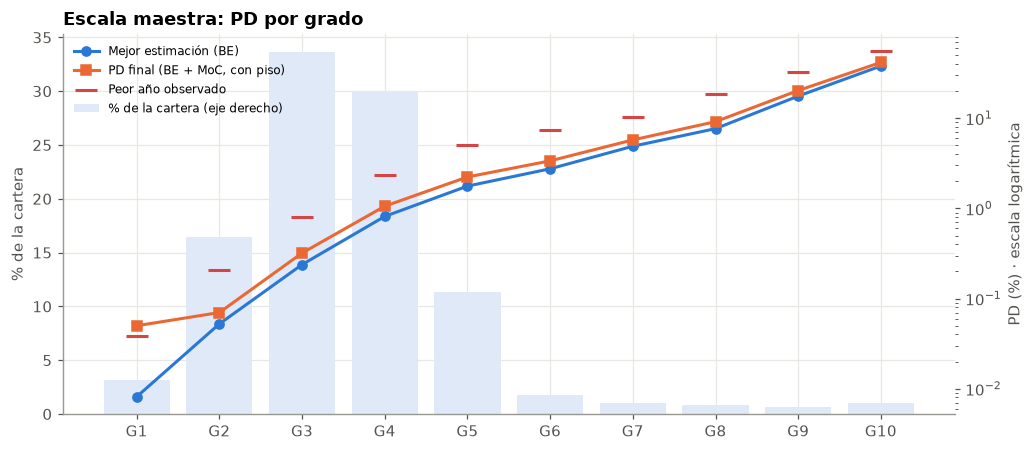

In [38]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
xg = np.arange(len(n_gt.index))
ax.bar(xg, escala['% de la cartera'], color='#dfe9f7', label='% de la cartera (eje derecho)')
ax.set_ylabel('% de la cartera')
ax2 = ax.twinx()
ax2.plot(xg, escala['BE (%)'], color=AZUL, marker='o', label='Mejor estimación (BE)')
ax2.plot(xg, escala['PD final (%)'], color=NARANJA, marker='s', label='PD final (BE + MoC, con piso)')
ax2.scatter(xg, escala['tasa máxima anual (%)'], color=ROJO, marker='_', s=200, label='Peor año observado')
ax2.set_yscale('log'); ax2.set_ylabel('PD (%) · escala logarítmica'); ax2.grid(False)
ax.set_xticks(xg); ax.set_xticklabels(escala.index)
ax.set_title('Escala maestra: PD por grado')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h2 + h1, l2 + l1, fontsize=8, loc='upper left')
mostrar(fig, 'escala_maestra')

## 10. Validación de la calibración

### Teoría: ¿cuántos defaults son demasiados?

Si un grado tiene 10,000 créditos y una PD de 1 %, esperamos unos 100 defaults. Si vemos 120, ¿la PD está mal o fue mala suerte?

**Prueba binomial.** Si los créditos fueran independientes, el número de defaults seguiría una distribución binomial. El p-valor es la probabilidad de ver tantos defaults o más con la PD asignada. Si es muy chico, la PD probablemente es baja.

**El problema: los defaults no son independientes.** En un mal año, todos los créditos empeoran a la vez. El **modelo de Vasicek** lo representa con un factor común *Z* (el estado de la economía) y una correlación ρ:

*DR(Z) = Φ( (Φ⁻¹(PD) − √ρ · Z) / √(1 − ρ) )*

En palabras: se pasa la PD a la escala de una normal, se desplaza según el año sea bueno o malo y se vuelve a pasar a probabilidad. Con ρ mayor, la tasa de un año puede alejarse mucho más de la PD.

In [39]:
j_n, j_pd = 10_000, 0.01
print(f'Esperados: {j_n * j_pd:.0f} defaults')
for j_obs in (110, 120, 130):
    print(f'  Observados {j_obs}: p-valor binomial (tantos o más) = {stats.binom.sf(j_obs - 1, j_n, j_pd):.3f}')

j_filas = []
for j_rho in (0.0001, 0.05, 0.15):
    j_dr = lambda z: stats.norm.cdf((stats.norm.ppf(j_pd) - np.sqrt(j_rho) * z) / np.sqrt(1 - j_rho))
    j_filas.append({'ρ': j_rho, 'tasa en un año bueno (Z = +1.645)': j_dr(1.645), 'tasa en un año típico (Z = 0)': j_dr(0),
                    'tasa en un año malo (Z = −1.645)': j_dr(-1.645), 'año muy malo (Z = −3.09)': j_dr(-3.09)})
pd.DataFrame(j_filas).round(4)

Esperados: 100 defaults
  Observados 110: p-valor binomial (tantos o más) = 0.169
  Observados 120: p-valor binomial (tantos o más) = 0.028
  Observados 130: p-valor binomial (tantos o más) = 0.002


,ρ,tasa en un año bueno (Z = +1.645),tasa en un año típico (Z = 0),tasa en un año malo (Z = −1.645),año muy malo (Z = −3.09)
0,0.0001,0.0096,0.0100,0.0104,0.0109
1,0.0500,0.0029,0.0085,0.0222,0.0467
2,0.1500,0.0007,0.0058,0.0335,0.1102


**Qué muestra el ejemplo.** Sin correlación, 130 defaults donde se esperaban 100 sería muy raro. Con ρ = 0.15, un año malo (1 de cada 20) puede tener una tasa de más del doble de la PD sin que la PD esté mal. Por eso la validación de un solo año tiene poca potencia: solo detecta desvíos enormes.

**Errores comunes**

- **Usar la prueba binomial independiente para una cartera.** Rechaza demasiado en los años malos.
- **Concluir que la PD es correcta porque un año pasó la prueba.** Con correlación, la evidencia se acumula año tras año.
- **Aplicar 10 pruebas a la vez y alarmarse por una.** Con 10 grados y un umbral del 5 %, se espera en promedio media falsa alarma.

> **Pruébalo.** Cambia `j_pd` a 0.001 (un grado bueno) y `j_n` a 2,000. ¿Cuántos defaults se esperan? ¿Cuántos harían falta para una alarma?

---

### Aplicación al proyecto

Validamos la **mejor estimación** (BE), porque es la que debe acertar en promedio. La PD final incluye un margen y, por diseño, debería quedar por encima de lo observado.

### Por grado: pruebas binomial y de Jeffreys

Para cada grado juntamos los años fuera de tiempo y preguntamos: **¿hubo más defaults de los que la PD permite esperar?** Es una pregunta de una sola cola, porque lo grave en riesgo es subestimar.

- **Binomial.** Si la PD del grado es correcta y los créditos son independientes, el número de defaults sigue una binomial. El p-valor es la probabilidad de ver tantos defaults o más.
- **Jeffreys.** Construye una distribución para la tasa verdadera del grado, `Beta(d + 0.5, n − d + 0.5)`, y mide qué parte queda por debajo de la PD asignada. Un valor pequeño indica que la PD probablemente es baja.

Ambas suponen independencia, y por eso rechazan demasiado en los años malos. Con varios grados, además, alguno puede salir significativo por azar. Las leemos junto con la prueba de cartera que sigue.

In [40]:
oot_h = hist[hist.corte.between(*CORTES_OOT)]
mapa_be = dict(zip(n_gt.index, BE)); mapa_final = dict(zip(n_gt.index, PD_FINAL))
filas = []
for g, d_ in oot_h.groupby('grado'):
    n, k = len(d_), int(d_['default'].sum())
    be, fin = mapa_be.get(g, BE[-1]), mapa_final.get(g, PD_FINAL[-1])
    filas.append({'grado': etiquetas_g[g], 'créditos-año': n, 'defaults': k, 'tasa OOT (%)': k / n * 100,
                  'BE (%)': be * 100, 'PD final (%)': fin * 100, 'esperados con BE': n * be,
                  'p binomial': stats.binom.sf(k - 1, n, be), 'p Jeffreys': stats.beta.cdf(be, k + 0.5, n - k + 0.5)})
val_grados = pd.DataFrame(filas).set_index('grado')
val_grados['semáforo'] = np.select([val_grados['p Jeffreys'] < 0.01, val_grados['p Jeffreys'] < 0.05], ['rojo', 'amarillo'], 'verde')
val_grados.round(4)

,créditos-año,defaults,tasa OOT (%),BE (%),PD final (%),esperados con BE,p binomial,p Jeffreys,semáforo
grado,,,,,,,,,
G1,42118,8,0.0190,0.0081,0.0500,3.4326,0.0242,0.0148,amarillo
G2,276257,112,0.0405,0.0524,0.0700,144.8173,0.9980,0.9977,verde
G3,712054,723,0.1015,0.2385,0.3203,1698.3162,1.0000,1.0000,verde
G4,666605,1718,0.2577,0.8163,1.0597,5441.3530,1.0000,1.0000,verde
G5,218538,1002,0.4585,1.7703,2.2359,3868.8495,1.0000,1.0000,verde
G6,41338,233,0.5636,2.7547,3.3733,1138.7288,1.0000,1.0000,verde
G7,22301,418,1.8744,4.8977,5.7601,1092.2459,1.0000,1.0000,verde
G8,16191,505,3.1190,7.6824,9.1777,1243.8572,1.0000,1.0000,verde
G9,15646,1087,6.9475,17.6395,20.3464,2759.8694,1.0000,1.0000,verde


**Lectura.**

- **En los años fuera de tiempo, lo observado queda por debajo de la BE en G2 a G10,** por ejemplo 0.26 % frente a 0.82 % en G4. Fueron años buenos y la PD es TTC, así que los p-valores cercanos a 1 son lo esperado. Estas pruebas de una cola solo detectan subestimación, no sobrestimación.
- **G1 sale en amarillo.** Hubo 8 defaults en 42,118 créditos-año, frente a 3.4 esperados con su BE de 0.0081 % (p binomial 0.024, Jeffreys 0.015). La BE de un grado con 8 defaults en 15 años es frágil. Con la PD final de 0.05 % se esperarían 21 defaults, así que el piso cubre la diferencia. Esto muestra para qué sirve un piso en bajo default.
- **Con 10 pruebas, una señal al 5 % puede ser azar,** porque se espera en promedio media falsa alarma. Aun así, la dirección es coherente con la fragilidad de G1. La recomendación es mantener el piso y vigilar G1 cada año.

### Cartera completa: bandas de Vasicek año por año

Si la PD TTC es correcta, la tasa de un año concreto igual se mueve con el ciclo. El modelo de Vasicek dice cuánto: con un factor común `Z` y correlación ρ, la tasa de default de una cartera grande, condicionada a `Z`, es

`DR(Z) = promedio de Φ( (Φ⁻¹(PD) − √ρ · Z) / √(1 − ρ) )`

Tomando los cuantiles de `Z` obtenemos una banda para cada año. Si la tasa observada cae dentro de la banda del 95 %, el año es coherente con la PD (verde). Entre 95 % y 99.9 % es una alerta (amarillo), y por encima del 99.9 % hay evidencia de que la PD es baja (rojo). Las bandas usan la composición de grados de cada año.

**¿Qué ρ usar?** Basilea fija 0.15 para hipotecas, un valor prudente pensado para el capital. También podemos estimar la correlación que implica nuestra propia historia: en el modelo de Vasicek, la varianza entre años de `Φ⁻¹(DR)` es `ρ / (1 − ρ)`. Mostramos ambas bandas. El semáforo usa la correlación implícita, porque con ρ = 0.15 la banda es tan ancha que casi ningún año podría quedar fuera.

ρ de Basilea: 0.15 | ρ implícito en las tasas anuales 2004–2018: 0.056


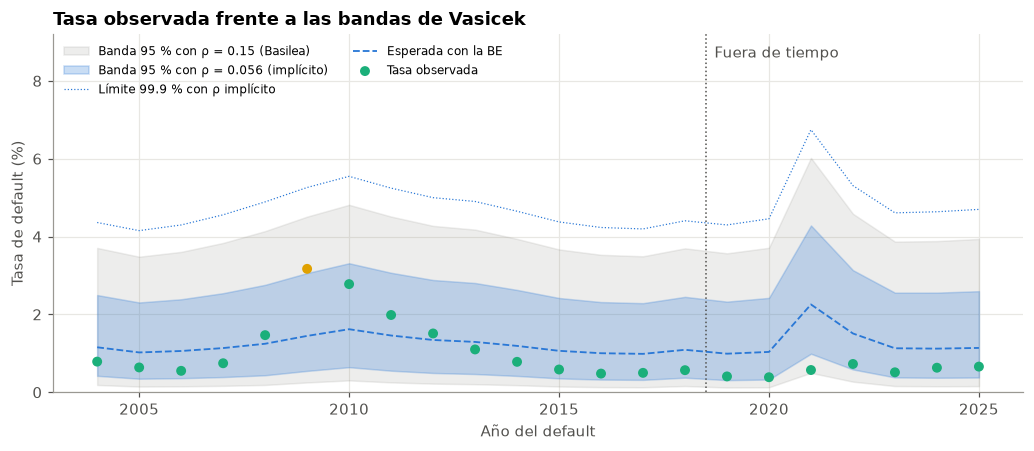

,muestra,tasa observada (%),esperada (%),q2.5,q97.5,q0.05 ρ est.,q2.5 ρ est.,q97.5 ρ est.,q99.95 ρ est.,banda 95 % ρ Basilea,semáforo
año del default,,,,,,,,,,,
2004,ciclo,0.787,1.155,0.187,3.708,0.220,0.422,2.497,4.361,dentro,verde
2005,ciclo,0.637,1.023,0.146,3.482,0.175,0.348,2.306,4.153,dentro,verde
2006,ciclo,0.550,1.060,0.152,3.606,0.182,0.361,2.389,4.298,dentro,verde
2007,ciclo,0.745,1.135,0.165,3.836,0.197,0.390,2.545,4.559,dentro,verde
2008,ciclo,1.467,1.246,0.188,4.140,0.223,0.437,2.759,4.891,dentro,verde
2009,ciclo,3.170,1.447,0.251,4.512,0.292,0.548,3.062,5.261,dentro,amarillo
2010,ciclo,2.778,1.619,0.304,4.815,0.349,0.644,3.314,5.547,dentro,verde
2011,ciclo,1.985,1.458,0.253,4.514,0.294,0.554,3.069,5.245,dentro,verde
2012,ciclo,1.510,1.343,0.221,4.274,0.259,0.495,2.884,4.999,dentro,verde


In [41]:
def banda(n_por_grado, pd_grado, q, rho=RHO):
    pz = stats.norm.cdf((stats.norm.ppf(pd_grado) + np.sqrt(rho) * stats.norm.ppf(q)) / np.sqrt(1 - rho))
    return np.sum(n_por_grado * pz) / np.sum(n_por_grado)

be_por_grado = pd.Series(BE, index=n_gt.index)
# Correlación implícita en el ciclo: en Vasicek, la varianza de Φ⁻¹(DR) entre años es ρ / (1 − ρ)
sigma2 = np.var(stats.norm.ppf(anual.loc[CORTES_CICLO[0]:CORTES_CICLO[1], 'tasa']), ddof=1)
RHO_ESTIMADO = sigma2 / (1 + sigma2)
print(f'ρ de Basilea: {RHO} | ρ implícito en las tasas anuales {CORTES_CICLO[0] + 1}–{CORTES_CICLO[1] + 1}: {RHO_ESTIMADO:.3f}')
filas = []
for c, d_ in hist[hist.corte.between(CORTES_CICLO[0], CORTES_OOT[1])].groupby('corte'):
    n_g = d_.groupby('grado').size()
    pdg = be_por_grado.reindex(n_g.index).fillna(BE[-1]).clip(lower=1e-6).to_numpy()
    filas.append({'año del default': c + 1, 'muestra': 'OOT' if c >= CORTES_OOT[0] else 'ciclo',
                  'tasa observada (%)': d_['default'].mean() * 100,
                  'esperada (%)': np.sum(n_g.to_numpy() * pdg) / n_g.sum() * 100,
                  **{f'q{q}': banda(n_g.to_numpy(), pdg, q / 100) * 100 for q in (2.5, 97.5)},
                  **{f'q{q} ρ est.': banda(n_g.to_numpy(), pdg, q / 100, RHO_ESTIMADO) * 100 for q in (0.05, 2.5, 97.5, 99.95)}})
vas = pd.DataFrame(filas).set_index('año del default')
vas['banda 95 % ρ Basilea'] = np.where(vas['tasa observada (%)'] > vas['q97.5'], 'fuera', 'dentro')
vas['semáforo'] = np.select([vas['tasa observada (%)'] > vas['q99.95 ρ est.'], vas['tasa observada (%)'] > vas['q97.5 ρ est.']],
                            ['rojo', 'amarillo'], 'verde')

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.fill_between(vas.index, vas['q2.5'], vas['q97.5'], color=GRIS, alpha=0.15, label=f'Banda 95 % con ρ = {RHO} (Basilea)')
ax.fill_between(vas.index, vas['q2.5 ρ est.'], vas['q97.5 ρ est.'], color=AZUL, alpha=0.25, label=f'Banda 95 % con ρ = {RHO_ESTIMADO:.3f} (implícito)')
ax.plot(vas.index, vas['q99.95 ρ est.'], color=AZUL, linewidth=0.8, linestyle=':', label='Límite 99.9 % con ρ implícito')
ax.plot(vas.index, vas['esperada (%)'], color=AZUL, linestyle='--', linewidth=1.2, label='Esperada con la BE')
colores = vas['semáforo'].map({'verde': VERDE, 'amarillo': '#e0a100', 'rojo': ROJO})
ax.scatter(vas.index, vas['tasa observada (%)'], c=colores, zorder=3, s=30, label='Tasa observada')
ax.axvline(CORTES_OOT[0] + 0.5, color=TINTA, linestyle=':', linewidth=1)
ax.text(CORTES_OOT[0] + 0.7, 8.6, 'Fuera de tiempo', color=TINTA)
ax.set(title='Tasa observada frente a las bandas de Vasicek', xlabel='Año del default', ylabel='Tasa de default (%)', ylim=(0, 9.2))
ax.legend(fontsize=8, loc='upper left', ncol=2)
mostrar(fig, 'validacion_vasicek')
vas.round(3)

**Lectura.**

- **La correlación implícita en la historia es 0.056,** menos de la mitad del 0.15 de Basilea. Para el capital, Basilea elige un valor prudente. Para validar, conviene contrastar con lo que muestran los datos.
- **Con ρ = 0.15, la banda del 95 % de un año típico va de alrededor de 0.15 % a casi 4 %,** tan ancha que todos los años quedan dentro, incluido 2009. Una prueba que nunca puede fallar no prueba nada.
- **Con la correlación implícita, 2009 sale en amarillo.** Su tasa de 3.17 % supera el límite del 95 % (3.06 %), pero no el del 99.9 % (5.26 %). El resto del ciclo queda en verde.
- **Todos los años fuera de tiempo quedan en verde,** con la tasa observada por debajo de la esperada: la PD TTC es conservadora en años buenos. En 2021, la esperada sube a 2.26 % por el efecto del *forbearance* sobre las variables de atraso, y la observada fue 0.57 %.
- **La prueba tiene poca potencia.** Con correlación, un solo año no puede demostrar que la PD esté bien. Solo puede alertar si se aleja mucho, y la evidencia se acumula año tras año.

## 11. Interpretabilidad con SHAP

### Teoría: repartir una predicción entre las variables

**La idea de SHAP.** La predicción de un crédito se escribe como la predicción promedio más un aporte de cada variable. Los aportes suman exactamente la diferencia. En una logística el reparto es directo: el aporte de cada variable es *coeficiente × (valor del crédito − valor promedio)*, en escala logit.

**Ejemplo mínimo.** Una logística con dos variables y tres créditos.

In [42]:
j_b0, j_b = -5.0, np.array([-0.8, -0.5])                  # intercepto y coeficientes (más WoE, menos riesgo)
j_X = pd.DataFrame({'woe_fico': [-1.2, 0.3, 1.0], 'woe_atraso': [-2.0, 0.4, 0.4]}, index=['crédito 1', 'crédito 2', 'crédito 3'])
j_base = j_b0 + j_X.mean().to_numpy() @ j_b
j_shap = (j_X - j_X.mean()) * j_b
j_res = j_shap.add_prefix('SHAP ').assign(**{'promedio (base)': j_base})
j_res['base + suma SHAP'] = j_base + j_shap.sum(axis=1)
j_res['logit del modelo'] = j_b0 + j_X.to_numpy() @ j_b
j_res['PD'] = sigmoide(j_res['logit del modelo'])
j_res.round(3)

,SHAP woe_fico,SHAP woe_atraso,promedio (base),base + suma SHAP,logit del modelo,PD
crédito 1,0.987,0.8,-4.827,-3.04,-3.04,0.046
crédito 2,-0.213,-0.4,-4.827,-5.44,-5.44,0.004
crédito 3,-0.773,-0.4,-4.827,-6.00,-6.00,0.002


**Qué muestra el ejemplo.** En cada crédito, la base más la suma de los SHAP da exactamente el logit del modelo. El crédito 1 tiene un FICO malo y atraso, y los dos aportes empujan su PD hacia arriba.

**Errores comunes**

- **Leer SHAP como causalidad.** Dice qué usó el modelo, no qué causa el default.
- **Mirar solo el promedio de |SHAP|.** Una variable rara, como el atraso, puede tener un efecto enorme en pocos créditos y verse poco importante en promedio.
- **Comparar SHAP de modelos en escalas distintas,** por ejemplo logit en uno y probabilidad en otro.

---

### Aplicación al proyecto

**Qué es un valor SHAP.** Para un crédito, el valor SHAP de una variable es cuánto mueve esa variable la predicción respecto del promedio de la cartera, en escala logit. La suma de los valores SHAP de todas las variables, más el promedio, da exactamente la predicción del crédito.

- En la **logística con WoE**, el valor SHAP es simplemente `coeficiente × (WoE del crédito − WoE promedio)`.
- En los **modelos de árboles**, LightGBM calcula los valores SHAP exactos con el algoritmo *Tree SHAP*.

Calculamos ambos sobre las **variables finalistas**, con 30,000 créditos-año al azar de la muestra OOT. Si los dos modelos coinciden en qué variables pesan más y en qué dirección, la explicación es más confiable.

**Cómo leer el gráfico de enjambre.** Cada punto es un crédito. Su posición horizontal es el valor SHAP: a la derecha aumenta la PD y a la izquierda la reduce. El color indica si el valor de la variable es bajo (azul) o alto (rojo), comparado con los demás créditos. Las variables categóricas aparecen en gris.

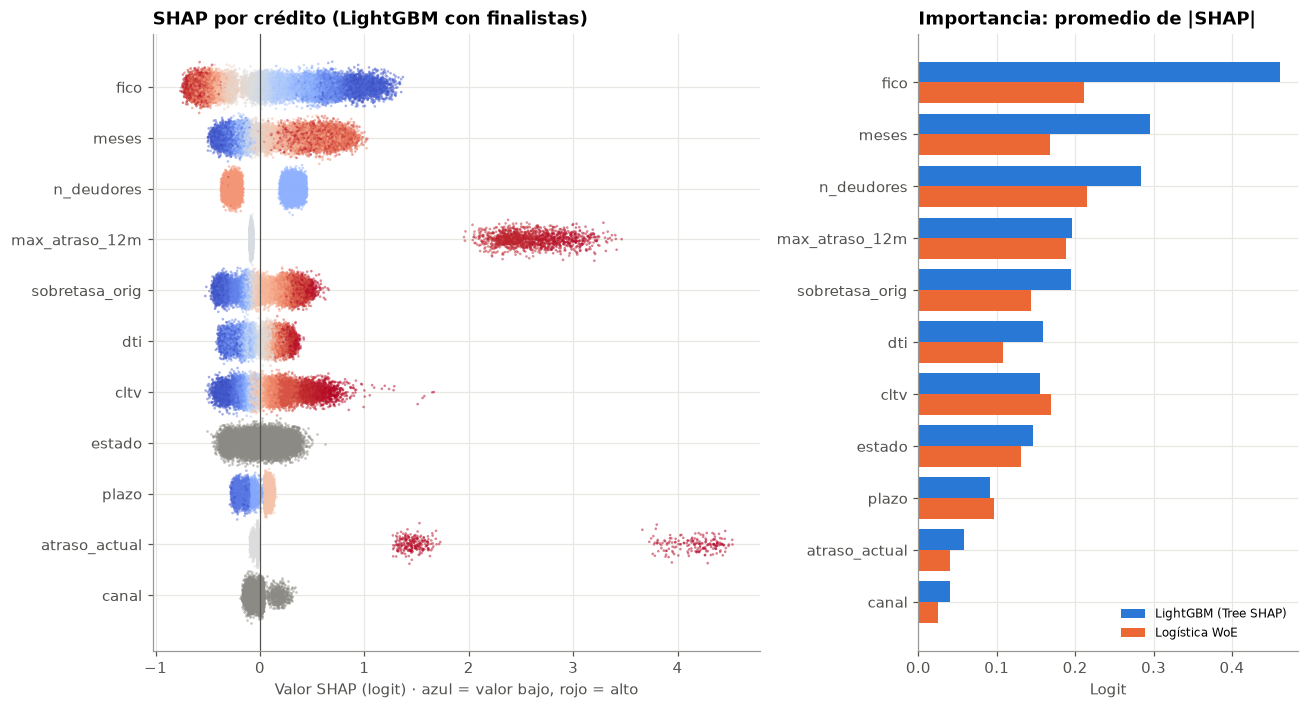

,LightGBM (Tree SHAP) (%),Logística WoE (%)
fico,22.2,14.1
meses,14.2,11.2
n_deudores,13.7,14.4
max_atraso_12m,9.4,12.6
sobretasa_orig,9.3,9.6
dti,7.7,7.2
cltv,7.4,11.3
estado,7.0,8.8
plazo,4.4,6.5
atraso_actual,2.8,2.7


In [43]:
muestra = oot.sample(30000, random_state=SEMILLA).reset_index(drop=True)
lgbm_fin = modelos['LightGBM finalistas'][0]
contrib = lgbm_fin.predict(muestra[finalistas], pred_contrib=True)
shap_arbol = pd.DataFrame(contrib[:, :-1], columns=finalistas)
W_m = matriz_woe(muestra, finalistas)
shap_log = (W_m - woe_train[finalistas].mean()) * modelo_log.coef_[0]
importancia = pd.DataFrame({'LightGBM (Tree SHAP)': shap_arbol.abs().mean(), 'Logística WoE': shap_log.abs().mean()})
importancia = importancia.sort_values('LightGBM (Tree SHAP)')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 0.45 * len(finalistas) + 1.6), gridspec_kw={'width_ratios': [1.6, 1]})
for i, v in enumerate(importancia.index):
    sv = shap_arbol[v].to_numpy()
    if v in CATEGORICAS:
        color = GRIS
    else:
        x = muestra[v].astype(float)
        color = plt.cm.coolwarm(x.rank(pct=True).fillna(0.5).to_numpy())
    jitter = np.random.default_rng(i).normal(0, 0.12, len(sv))
    a1.scatter(sv, i + jitter, c=color, s=3, alpha=0.5, linewidths=0)
a1.axvline(0, color=TINTA, linewidth=0.8)
a1.set_yticks(range(len(importancia))); a1.set_yticklabels(importancia.index)
a1.set(title='SHAP por crédito (LightGBM con finalistas)', xlabel='Valor SHAP (logit) · azul = valor bajo, rojo = alto')
pos = np.arange(len(importancia))
a2.barh(pos + 0.2, importancia['LightGBM (Tree SHAP)'], height=0.4, color=AZUL, label='LightGBM (Tree SHAP)')
a2.barh(pos - 0.2, importancia['Logística WoE'], height=0.4, color=NARANJA, label='Logística WoE')
a2.set_yticks(pos); a2.set_yticklabels(importancia.index)
a2.set(title='Importancia: promedio de |SHAP|', xlabel='Logit'); a2.legend(fontsize=8, loc='lower right')
mostrar(fig, 'shap_finalistas')
(importancia.iloc[::-1] / importancia.sum() * 100).round(1).rename(columns=lambda c: f'{c} (%)')

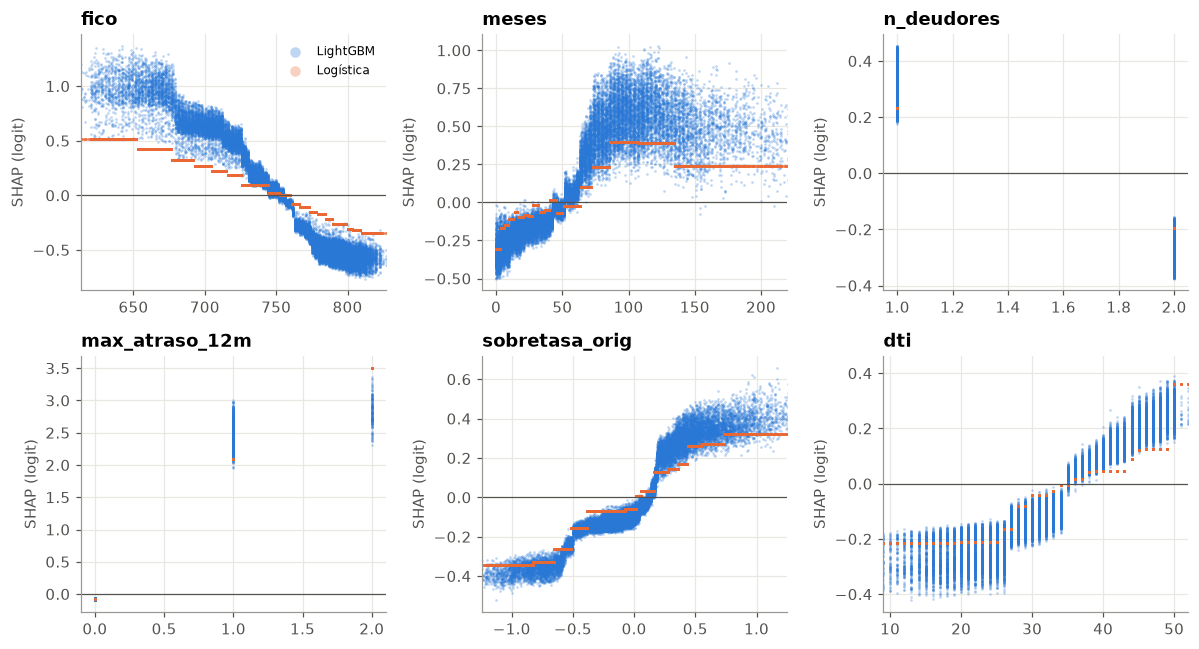

In [44]:
top = [v for v in importancia.index[::-1] if v not in CATEGORICAS][:6]
fig, ejes = plt.subplots(2, 3, figsize=(11, 6))
for ax, v in zip(ejes.flat, top):
    x = muestra[v].astype(float)
    ax.scatter(x, shap_arbol[v], s=3, alpha=0.3, color=AZUL, linewidths=0, label='LightGBM')
    ax.scatter(x, shap_log[v], s=3, alpha=0.3, color=NARANJA, linewidths=0, label='Logística')
    ax.axhline(0, color=TINTA, linewidth=0.8)
    lo, hi = np.nanpercentile(x, [1, 99])
    ax.set(title=v, xlim=(lo - (hi - lo) * 0.05, hi + (hi - lo) * 0.05), ylabel='SHAP (logit)')
ejes.flat[0].legend(fontsize=8, markerscale=4)
mostrar(fig, 'shap_dependencia')

**Lectura.**

- **Los dos modelos coinciden en las variables importantes:** FICO, antigüedad, número de deudores, historial de atraso, sobretasa, DTI, CLTV y estado. En LightGBM, el FICO explica el 22 % de la importancia; en la logística, el 14 %.
- **El promedio de |SHAP| subestima al atraso.** Solo el 3 % de los créditos tuvo atraso, pero en ellos el efecto es enorme: entre +2 y +3.5 en logit para `max_atraso_12m`, lo que multiplica las chances de default por 7 a 33. Si el atraso sigue vigente al corte, `atraso_actual` suma cerca de +1.5 con 30 días y +4.2 con 60 días. El gráfico de enjambre lo muestra mejor que el de barras.
- **Las direcciones son las esperadas.** El riesgo sube con menor FICO, mayor DTI, mayor CLTV y mayor sobretasa, y cuando hay un solo deudor (+0.2 a +0.45 en logit, frente a −0.2 a −0.37 con dos).
- **La antigüedad (`meses`) merece cuidado.** El riesgo sube hasta unos 100 meses y luego se aplana. En los cortes 2013–2017, un crédito de 85 a 134 meses fue originado entre 2005 y 2008, en la burbuja. El efecto mezcla edad con calidad de la cosecha. En 2024, esas edades corresponden a cosechas de 2013 a 2016, de mejor calidad, así que el modelo podría sobrestimar su riesgo.
- **LightGBM dibuja curvas suaves y la logística, escalones.** En el FICO, la logística aplana los extremos: sus tramos no capturan cuánto más riesgo hay por debajo de 650. Ahí está buena parte de la ventaja de los árboles, que con las mismas variables ganan 0.011 de Gini fuera de tiempo.

## 12. Sensibilidad

Un resultado robusto no debería depender de un detalle. Hacemos cinco preguntas, sin usar las respuestas para volver a elegir el modelo:

1. **¿Y si cambia la definición del default?** Evaluamos el score elegido contra el default sin excluir alivios y sin contar reestructuras.
2. **¿Cuánto aportan las variables de comportamiento?** Reentrenamos la logística solo con variables de originación.
3. **¿Y si el desarrollo incluye los años posteriores a la crisis?** Reentrenamos con los cortes 2010–2017.
4. **¿Cambia si validamos al azar?** Validación cruzada de 10 particiones por crédito dentro del desarrollo. `Q1` es el valor que deja por debajo al 25 % de los resultados.
5. **¿Y si el atraso durante un alivio tampoco contara en las variables?** Así variables y objetivo usarían la misma regla. Reajustamos los tramos de las variables de atraso y la logística con las mismas finalistas.

La sensibilidad de la tendencia central ya está en la sección 9.

In [45]:
sens = []
# 1. Definiciones alternativas del default, sobre las filas elegibles en ambas
alt = preparar(cohortes.filter(pl.col(elig_col) & pl.col('corte').is_between(*CORTES_OOT)))
extra = cohortes.filter(pl.col(elig_col) & pl.col('corte').is_between(*CORTES_OOT)).select(
    'elig_ev_bruto', 'y_ev_bruto', 'elig_ev_sinmod', 'y_ev_sinmod').to_pandas()
s_alt = f_elegido(alt)
for nombre, e, y_ in [('Sin excluir alivios', 'elig_ev_bruto', 'y_ev_bruto'), ('Sin reestructuras', 'elig_ev_sinmod', 'y_ev_sinmod')]:
    m = extra[e].to_numpy()
    sens.append({'prueba': f'1. Default: {nombre.lower()}', 'Gini OOT': 2 * roc_auc_score(extra.loc[m, y_], s_alt[m]) - 1,
                 'tasa OOT': extra.loc[m, y_].mean()})
sens.insert(0, {'prueba': 'Modelo elegido (referencia)', 'Gini OOT': punt_oot[ELEGIDO][0], 'tasa OOT': pi_oot})

# 2. Solo originación
orig_fin = [v for v in finalistas if v in ORIGINACION or v in CATEGORICAS]
m2, _ = ajustar_logistica(woe_train[orig_fin], train.default)
sens.append({'prueba': f'2. Solo originación ({len(orig_fin)} variables)',
             'Gini OOT': 2 * roc_auc_score(y_oot, m2.predict_proba(matriz_woe(oot, orig_fin))[:, 1]) - 1, 'tasa OOT': pi_oot})

# 3. Ventana de desarrollo más larga
largo = datos[datos.corte.between(2010, CORTES_DESARROLLO[1]) & ~datos.id.isin(ids_test)]
m3, _ = ajustar_logistica(matriz_woe(largo, finalistas), largo.default)
sens.append({'prueba': '3. Desarrollo 2010–2017', 'Gini OOT': 2 * roc_auc_score(y_oot, m3.predict_proba(matriz_woe(oot, finalistas))[:, 1]) - 1,
             'tasa OOT': pi_oot})

# 4. Validación cruzada aleatoria por crédito
dev_all = pd.concat([train, test], ignore_index=True)
W_dev = matriz_woe(dev_all, finalistas)
pliegue = pd.Series(np.random.default_rng(SEMILLA).integers(0, 10, dev_all.id.nunique()), index=dev_all.id.unique())[dev_all.id].to_numpy()
ginis_cv = []
for k in range(10):
    m4, _ = ajustar_logistica(W_dev[pliegue != k], dev_all.default[pliegue != k])
    ginis_cv.append(2 * roc_auc_score(dev_all.default[pliegue == k], m4.predict_proba(W_dev[pliegue == k])[:, 1]) - 1)
sens.append({'prueba': f'4. Validación cruzada 10 particiones: media (Q1 {np.percentile(ginis_cv, 25):.3f})',
             'Gini OOT': np.mean(ginis_cv), 'tasa OOT': dev_all.default.mean()})
# 5. Variables de atraso que también excluyen los meses de alivio
datos_aj = preparar(cohortes.filter(pl.col(elig_col) & pl.col('corte').is_between(CORTES_DESARROLLO[0], CORTES_OOT[1])),
                    atraso_sin_alivio=not ATRASO_SIN_ALIVIO)
tr_aj = datos_aj[datos_aj.corte.between(*CORTES_DESARROLLO) & datos_aj.id.isin(set(train.id))]
oot_aj = datos_aj[datos_aj.corte.between(*CORTES_OOT)]
atraso = ['meses_mora_12m', 'max_atraso_12m', 'atraso_actual']
tramos_aj = {v: (ajustar_tramos(tr_aj[v], tr_aj.default, v) if v in atraso else tramos[v]) for v in finalistas}
W_aj = lambda d: pd.DataFrame({v: transformar(d[v], tramos_aj[v]) for v in finalistas})
m5, _ = ajustar_logistica(W_aj(tr_aj), tr_aj.default)
s5 = m5.predict_proba(W_aj(oot_aj))[:, 1]
sens.append({'prueba': '5. Atraso ' + ('con' if ATRASO_SIN_ALIVIO else 'sin') + ' los meses de alivio en las variables',
             'Gini OOT': 2 * roc_auc_score(oot_aj.default, s5) - 1, 'tasa OOT': oot_aj.default.mean()})
gini_5_anio = pd.DataFrame({'elegido': por_anio[f'Gini {ELEGIDO}'],
                            'atraso sin alivio': [2 * roc_auc_score(oot_aj.default[oot_aj.corte == c], s5[(oot_aj.corte == c).to_numpy()]) - 1
                                                  for c in range(CORTES_OOT[0], CORTES_OOT[1] + 1)]}, index=por_anio.index)
sens = pd.DataFrame(sens).set_index('prueba')
sens['tasa OOT'] = sens['tasa OOT'].map(pct)
display(sens.round(3))
print('Gini por año del default con cada versión de las variables de atraso')
gini_5_anio.round(3)

,Gini OOT,tasa OOT
prueba,,
Modelo elegido (referencia),0.776,0.55 %
1. Default: sin excluir alivios,0.514,1.09 %
1. Default: sin reestructuras,0.759,0.50 %
2. Solo originación (8 variables),0.506,0.55 %
3. Desarrollo 2010–2017,0.793,0.55 %
4. Validación cruzada 10 particiones: media (Q1 0.804),0.806,0.58 %
5. Atraso sin los meses de alivio en las variables,0.637,0.55 %


Gini por año del default con cada versión de las variables de atraso


,elegido,atraso sin alivio
año del default,,
2019,0.785,0.766
2020,0.617,0.608
2021,0.868,0.523
2022,0.891,0.554
2023,0.752,0.636
2024,0.739,0.675
2025,0.746,0.700


**Lectura.**

1. **La definición del default pesa más que el algoritmo.** Sin excluir los alivios, el Gini cae a 0.514 y la tasa sube a 1.09 %: los atrasos del COVID no se pueden anticipar con el historial. Sin contar reestructuras, el Gini es 0.759 y la tasa 0.50 %.
2. **El comportamiento aporta 0.27 de Gini.** Solo con variables de originación, el Gini es 0.506. Un modelo de admisión sería mucho más débil, porque al otorgar el crédito no hay historial de pagos.
3. **Un desarrollo más largo (2010–2017) mejora el Gini fuera de tiempo a 0.793 (+0.017).** Es un candidato para la siguiente versión. No lo usamos para cambiar la elección, porque eso convertiría la prueba fuera de tiempo en una muestra más de ajuste.
4. **La validación cruzada aleatoria da 0.806 (Q1 0.804),** por encima del 0.776 fuera de tiempo. Mezclar años al azar sobreestima el desempeño futuro, igual que en cualquier problema con cambio temporal.
5. **Excluir el atraso en alivio de las variables baja el Gini a 0.637.** En 2021 y 2022 cae de 0.87–0.89 a 0.52–0.55. **El atraso durante el *forbearance* era la mejor señal de quién incumpliría al terminar el alivio.** Que la variable objetivo no lo cuente como default no significa que las variables deban ignorarlo: una cosa es definir el evento y otra usar toda la información observable.

## 13. Uso en la gestión: qué cambia en el capital

### Teoría: de la PD al capital

El capital regulatorio cubre las **pérdidas inesperadas**: lo que se perdería en un año muy malo (1 de cada 1,000) por encima de la pérdida esperada. La fórmula de Basilea usa el mismo modelo de Vasicek de la sección 10, evaluado en ese año extremo:

*K = LGD × [ Φ( (Φ⁻¹(PD) + √ρ · Φ⁻¹(0.999)) / √(1 − ρ) ) − PD ]*

- La primera parte es la tasa de default del año extremo.
- Se le resta la PD, porque la pérdida esperada se cubre con provisiones.
- Los activos ponderados por riesgo (APR) son *12.5 × K × exposición*. La **densidad de APR** es APR ÷ exposición.

In [46]:
def j_capital(pd_, lgd=0.25, rho=0.15):
    extremo = stats.norm.cdf((stats.norm.ppf(pd_) + np.sqrt(rho) * stats.norm.ppf(0.999)) / np.sqrt(1 - rho))
    return lgd * (extremo - pd_)

j_pds = np.array([0.0005, 0.005, 0.01, 0.02, 0.05])
pd.DataFrame({'PD': j_pds, 'K (% de la exposición)': j_capital(j_pds) * 100,
              'densidad de APR (%)': 12.5 * j_capital(j_pds) * 100}).round(3)

,PD,K (% de la exposición),densidad de APR (%)
0,0.000,0.277,3.461
1,0.005,1.559,19.488
2,0.010,2.507,31.333
3,0.020,3.908,48.853
4,0.050,6.588,82.346


**Qué muestra el ejemplo.** El capital crece con la PD, pero no en proporción: pasar de 0.5 % a 1 % no duplica el capital. Aun así, subestimar la PD a la mitad deja al banco con bastante menos capital del que corresponde.

**Errores comunes**

- **Usar una PD sin calibrar al ciclo para capital.** En años buenos daría un capital demasiado bajo.
- **Tomar las cifras como capital real** cuando la LGD es ilustrativa.

---

### Aplicación al proyecto

La PD alimenta las provisiones, el precio y el capital. Para ilustrar el efecto de la calibración usamos la fórmula de capital de Basilea para hipotecas residenciales:

`K = LGD × [ Φ( (Φ⁻¹(PD) + √ρ · Φ⁻¹(0.999)) / √(1 − ρ) ) − PD ]`, con ρ = 0.15, y activos ponderados por riesgo = `12.5 × K × exposición`.

Comparamos tres PD sobre la cartera vigente al cierre de 2024: la del modelo sin calibrar (el nivel de los años buenos del desarrollo), la mejor estimación del ciclo y la PD final. La LGD de 25 % es ilustrativa: la pérdida dado el default requiere su propio modelo.

In [47]:
def capital(pd_, lgd=LGD_ILUSTRATIVA, rho=RHO):
    pd_ = np.clip(pd_, 1e-6, 0.999)
    return lgd * (stats.norm.cdf((stats.norm.ppf(pd_) + np.sqrt(rho) * stats.norm.ppf(0.999)) / np.sqrt(1 - rho)) - pd_)

cartera = hist[hist.corte == CORTES_OOT[1]].copy()
cartera['pd_be'] = be_por_grado.reindex(cartera['grado']).fillna(BE[-1]).to_numpy()
cartera['pd_final'] = pd.Series(PD_FINAL, index=n_gt.index).reindex(cartera['grado']).fillna(PD_FINAL[-1]).to_numpy()
expo = cartera['saldo'].to_numpy()
filas = []
for nombre, col in [('Modelo sin calibrar (nivel 2014–2018)', 'pd_bruta'), ('Mejor estimación del ciclo (BE)', 'pd_be'),
                    ('PD final (BE + MoC, con piso)', 'pd_final')]:
    p_ = cartera[col].to_numpy()
    filas.append({'PD': nombre, 'PD promedio ponderada por saldo': np.average(p_, weights=expo),
                  'pérdida esperada / saldo': np.average(p_ * LGD_ILUSTRATIVA, weights=expo),
                  'densidad de APR': np.average(12.5 * capital(p_), weights=expo)})
uso = pd.DataFrame(filas).set_index('PD')
print(f'Cartera al cierre de {CORTES_OOT[1]}: {len(cartera):,} créditos | tasa de default observada en {CORTES_OOT[1] + 1}: '
      f'{pct(cartera.default.mean())}')
uso.map(pct)

Cartera al cierre de 2024: 321,974 créditos | tasa de default observada en 2025: 0.66 %


,PD promedio ponderada por saldo,pérdida esperada / saldo,densidad de APR
PD,,,
Modelo sin calibrar (nivel 2014–2018),0.56 %,0.14 %,12.85 %
Mejor estimación del ciclo (BE),1.05 %,0.26 %,22.28 %
"PD final (BE + MoC, con piso)",1.28 %,0.32 %,26.11 %


**Lectura.**

- **Sin calibrar, el modelo da una PD promedio de 0.56 %,** cercana al 0.66 % observado en 2025. Funciona como una PD del momento (PIT) para años buenos.
- **La calibración al ciclo duplica la PD** (1.05 %), y el margen la lleva a 1.28 %.
- **La densidad de APR pasa de 12.9 % a 22.3 % con la BE y a 26.1 % con la PD final.** Con la PD sin calibrar, el capital sería aproximadamente la mitad del que corresponde a la PD final.
- **Por eso importa la calibración.** Con el nivel de los años buenos, un año como 2009 (3.17 %) encontraría al banco con la mitad del capital. La pérdida esperada sigue la misma lógica: 0.14 % del saldo sin calibrar y 0.32 % con la PD final.

## 14. Ficha del modelo

Una ficha de modelo reúne en un solo lugar qué hace el modelo, con qué datos se construyó y qué tan bien funciona. Sirve para que otra persona pueda usarlo, cuestionarlo o auditarlo sin revisar todo el código.

In [48]:
ficha = {
    'Modelo': f'{ELEGIDO}, calibrado al ciclo y llevado a una escala maestra de {len(n_gt.index)} grados',
    'Variables': ', '.join(finalistas),
    'Definición de default': '90+ días, cierre con pérdida o reestructura en los 12 meses siguientes; se excluye el atraso en forbearance o desastre',
    'Entrenamiento': f'{len(train):,} créditos-año de los cortes {CORTES_DESARROLLO[0]}–{CORTES_DESARROLLO[1]}, {int(train.default.sum()):,} defaults',
    'Prueba de desarrollo': f'{len(test):,} créditos-año, Gini {punt_test[ELEGIDO][0]:.3f} ({ic(boot_test[ELEGIDO][:, 0])})',
    'Prueba fuera de tiempo': f'{len(oot):,} créditos-año de los cortes {CORTES_OOT[0]}–{CORTES_OOT[1]}, tasa {pct(pi_oot)}',
    'Gini OOT (IC 95 %)': f'{punt_oot[ELEGIDO][0]:.3f} ({ic(boot_oot[ELEGIDO][:, 0])})',
    'PR AUC OOT frente a la tasa': f'{punt_oot[ELEGIDO][1]:.3f} frente a {pi_oot:.4f}',
    'Tendencia central': f'{pct(TENDENCIA_CENTRAL)} (cortes {CORTES_CICLO[0]}–{CORTES_CICLO[1]}, promedio simple); desplazamiento logit {DELTA:+.3f}',
    'Margen de conservadurismo': f'Percentil {int(CUANTIL_MOC * 100)} del bootstrap de años; piso de {pct(PD_PISO)}',
    'Validación de calibración OOT': f"Grados en verde: {(val_grados['semáforo'] == 'verde').sum()} de {len(val_grados)}; "
                                     f"años OOT en verde con ρ implícito: {(vas.loc[vas.muestra == 'OOT', 'semáforo'] == 'verde').sum()} de {(vas.muestra == 'OOT').sum()}",
}
display(pd.DataFrame({'Valor': ficha}))

,Valor
Modelo,"Logística WoE, calibrado al ciclo y llevado a ..."
Variables,"max_atraso_12m, atraso_actual, fico, meses, so..."
Definición de default,"90+ días, cierre con pérdida o reestructura en..."
Entrenamiento,"913,163 créditos-año de los cortes 2013–2017, ..."
Prueba de desarrollo,"392,136 créditos-año, Gini 0.804 (0.791 a 0.817)"
Prueba fuera de tiempo,"2,034,470 créditos-año de los cortes 2018–2024..."
Gini OOT (IC 95 %),0.776 (0.769 a 0.783)
PR AUC OOT frente a la tasa,0.183 frente a 0.0055
Tendencia central,"1.18 % (cortes 2003–2017, promedio simple); de..."
Margen de conservadurismo,Percentil 90 del bootstrap de años; piso de 0....


**Diccionario de las variables finales**

La definición de cada variable está en la tabla de candidatas de la sección 6, y sus tramos y WoE en `tabla_tramos(tramos['<variable>'])`. Todas se calculan con información disponible al 31 de diciembre del año de corte.

## 15. Limitaciones y monitoreo

**Limitaciones**

- **Es una muestra, no la cartera de un banco.** Cada cosecha aporta 50,000 créditos sin importar su volumen real. Las cosechas grandes, como las de 2003 o 2021, pesan menos de lo que pesarían en una cartera real, y la tendencia central podría cambiar con los pesos verdaderos.
- **Solo hipotecas estándar de Freddie Mac:** tasa fija, documentación completa y sin garantía del gobierno. No representa créditos *subprime*, FHA o VA.
- **No hay variables macro ni valor actual del inmueble.** El LTV estimado de Freddie Mac solo existe desde 2017. El modelo no puede anticipar una crisis, y la calibración TTC compensa el nivel, pero no el momento.
- **El COVID fue una situación nueva.** El desarrollo no tuvo *forbearance*, así que el modelo trató el atraso en alivio como atraso real. Eso ayudó a ordenar en 2021–2022, pero infló la PD de 2021.
- **La antigüedad mezcla edad y cosecha.** El efecto de `meses` refleja en parte la mala calidad de las cosechas de 2005–2008.
- **Un prepago cuenta como "sin default".** Es la convención del método de cohortes, pero el prepago compite con el default y es frecuente en hipotecas.
- **Un crédito que se cura después del default no vuelve a la cartera elegible.** Una cartera real seguiría calculando su PD.
- **La prueba fuera de tiempo no es totalmente ciega.** El tamaño mínimo de tramo, la agrupación de variables discretas y el tratamiento del atraso en alivio se revisaron después de ver resultados fuera de tiempo. La regla de elección del modelo no cambió.
- **Las pruebas por grado suponen independencia** y se aplican a 10 grados a la vez. La correlación implícita se estima con solo 15 años y una crisis.
- **La LGD es ilustrativa,** así que las cifras de capital solo sirven para comparar las PD entre sí.

**Plan de monitoreo propuesto**

| Indicador | Frecuencia | Verde | Revisar | Actuar |
|---|---|---|---|---|
| PSI del score frente al entrenamiento | Trimestral | ≤ 0.10 | 0.10 a 0.25 | > 0.25 |
| Gini con defaults maduros (12 meses) | Anual | ≥ 0.70 | 0.60 a 0.70 | < 0.60 |
| Tasa observada frente a la banda de Vasicek (ρ implícito) | Anual | Dentro del 95 % | Entre 95 % y 99.9 % | Fuera del 99.9 % |
| Prueba de Jeffreys por grado | Anual | p ≥ 0.05 | 0.01 a 0.05 | < 0.01 |
| Cartera en *forbearance* o desastre | Mensual | < 1 % | 1 % a 5 % | > 5 %: revisar variables y definición |

Estos umbrales son una propuesta inicial basada en lo observado aquí, y deben ajustarse con la experiencia. Recalibrar la tendencia central una vez al año, incorporando los años nuevos. Reentrenar si el Gini cae por debajo de 0.60 dos años seguidos, o si cambia la política de originación.

## Conclusión: ¿qué PD asignamos?

**Respuesta.** A cada crédito le asignamos la PD de su grado en una escala maestra de 10 grados. Una regresión logística con 11 variables ordena el riesgo; la calibración al ciclo, de 2004 a 2018, fija el nivel, y un margen de conservadurismo cubre la incertidumbre de haber visto una sola crisis.

| Grado | % del ciclo | Mejor estimación | PD final |
|---|---|---|---|
| G1 | 3.2 % | 0.008 % | 0.050 % (piso) |
| G2 | 16.5 % | 0.052 % | 0.070 % |
| G3 | 33.6 % | 0.239 % | 0.320 % |
| G4 | 30.0 % | 0.816 % | 1.060 % |
| G5 | 11.3 % | 1.770 % | 2.236 % |
| G6 | 1.8 % | 2.755 % | 3.373 % |
| G7 | 1.1 % | 4.898 % | 5.760 % |
| G8 | 0.9 % | 7.682 % | 9.178 % |
| G9 | 0.6 % | 17.639 % | 20.346 % |
| G10 | 1.0 % | 38.063 % | 41.719 % |

**Resultados principales**

| Medida | Valor |
|---|---|
| Gini fuera de tiempo, 2019–2025 (IC 95 %) | 0.776 (0.769 a 0.783) |
| PR AUC fuera de tiempo frente a la tasa | 0.183 frente a 0.0055 |
| Tasa del desarrollo frente a la tendencia central | 0.57 % frente a 1.18 % |
| PD promedio de la cartera de 2024: sin calibrar, BE y final | 0.56 %, 1.05 % y 1.28 % |
| Densidad de APR con la PD sin calibrar y con la final | 12.9 % y 26.1 % |

**Qué decidimos y por qué**

- **La logística en lugar de LightGBM.** Cede 0.015 de Gini fuera de tiempo a cambio de ser transparente, estable y fácil de auditar. La diferencia es real, pero menor que la tolerancia fijada antes de ver resultados.
- **Calibrar al ciclo y no a los años del desarrollo.** El desarrollo tiene una tasa de 0.57 %; el ciclo, 1.18 %. Sin calibrar, la PD subestimaría una crisis como la de 2009 por un factor de más de 3, y el capital sería la mitad.
- **Un piso y un margen para los grados con pocos defaults.** El mejor grado tuvo 8 defaults en 15 años. En la prueba fuera de tiempo, su mejor estimación quedó corta y el piso cubrió la diferencia.

**Las ideas para llevarse**

1. En una cartera de bajo default, lo difícil no es ordenar, sino fijar el nivel: el modelo ordena con un Gini de 0.78, pero los años del desarrollo muestran la mitad del riesgo del ciclo.
2. La definición del default importa más que el algoritmo. Contar el *forbearance* como default bajaría el Gini de 0.78 a 0.51.
3. Con eventos raros, los tramos se dimensionan por defaults, no por población. Un mínimo de 2 % de la población borraría el tramo de los créditos con atraso al corte, que concentran el riesgo.
4. Cero defaults observados no significa PD cero. El piso de Jeffreys y el regulatorio existen por eso, y Pluto–Tasche muestra cuánto cuesta el supuesto más prudente.
5. Validar una PD de bajo default tiene poca potencia. Con correlación, un año no demuestra nada, y por eso la evidencia se acumula con el tiempo.
6. Definir el evento y elegir la información son decisiones distintas. El atraso durante un alivio no es default, pero es la mejor señal del default que viene.

## Ejercicios

1. **Cambia `EXCLUIR_ALIVIO` a `False`.** ¿Qué le pasa a la tasa de 2020 y a la tendencia central si el ciclo incluyera ese año? ¿Qué le dirías a quien quiera usar esa cifra?
2. **Cambia `CORTES_CICLO` a `(2005, 2017)` y luego a `(2010, 2017)`.** ¿Cómo cambia la PD final del grado G1? ¿Qué ciclo te parece defendible y por qué?
3. **Cambia `TOLERANCIA_GINI` a 0.** ¿Qué modelo se elige? ¿Lo pondrías en producción?
4. **Cambia `RHO` a 0.05 y a 0.25.** ¿Cuántos años quedan fuera de la banda de Vasicek? ¿Qué te dice eso sobre la elección de ρ?
5. **Cambia `CONFIANZA_PT` a 0.75 y a 0.99.** Compara las cotas de Pluto–Tasche con la PD final. ¿Cuál es más conservadora y por qué?
6. **Cambia `MIN_DEFAULTS_TRAMO` a 10 y a 100.** ¿Cuántos tramos tiene `fico`? ¿Cambian las finalistas?
7. **Para pensar:** el modelo con solo variables de originación ordena peor, pero se podría usar al otorgar el crédito. ¿Para qué decisiones usarías cada uno?